# EDA: player-game fantasy points

**Problem.** Fantasy football managers in a full-PPR Sleeper league choose each week which QB/RB/WR/TE to start.
The goal is an independent model that predicts a player's **actual fantasy points in a game** more accurately than
Sleeper's weekly projection, so the app's lineup and waiver advice can use it. **No weekly (per-game) projection
from any platform is a feature**; yearly preseason rankings are allowed. Sleeper's weekly projection lives in a
separate benchmark file and is not read here.
**Target:** `act`, continuous (PPR points, can be slightly negative, 0 when the player did not play).
**Unit of observation:** one player in one regular-season week, if he was on the 53-man roster, recently active
or preseason-ranked, and not listed Out (defined from facts, not from any projection); key
`player_id, season, week`. The same player repeats across weeks (entity = `player_id`).
**Timeline:** every feature is known before kickoff (history features use only earlier games; preseason
rankings are frozen at week 1; the injury report is published before the game). The target is
realized at the end of the game. Column definitions: `../DATA_DICTIONARY.md`; how Sleeper itself performs:
`../01_sleeper_vs_actual.ipynb`.

**Split.** Already split by time: train = 2022-2025, test = 2026 weeks 1-7. Sections 1-11 use train only;
the test set appears only in section 12.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import scikit_posthocs as sp
from pathlib import Path
from scipy import stats
from rapidfuzz import fuzz
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.multitest import multipletests
import lightgbm as lgb

FIG = Path("figures")
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 80)
SEED = 0

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=110)
    plt.show()

df_raw = pd.read_parquet("../data/player_games_train.parquet")
test_raw = pd.read_parquet("../data/player_games_test.parquet")
df = df_raw.copy()
cleaning_log = []  # (step, column, rows affected, action)
TARGET, ENTITY, KEY = "act", "player_id", ["player_id", "season", "week"]
print("train", df.shape, "test", test_raw.shape, "| test has target:", TARGET in test_raw)

train (31269, 75) test (3069, 75) | test has target: True


## 1. First look
Shape, types, a column-type classification used by every later section, the grain check, and the target's
missing count.

In [2]:
print(f"memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
df.head(3).T

memory: 19.8 MB


,0,1,2
season,2022,2022,2022
week,1,1,1
team,IND,LV,TEN
position,QB,RB,QB
gsis_id,00-0029567,00-0029239,00-0029701
...,...,...,...
opp_sack_rate_rel_l8,-0.017,-0.010,-0.008
opp_points_allowed_rel_l8,1.707,6.332,2.457
opp_plays_allowed_rel_l8,1.758,2.258,3.508
opp_pts_allowed_rel_l8,0.474,1.553,-1.866


In [3]:
def classify(s: pd.Series) -> str:
    if s.name == TARGET:
        return "target"
    if s.name in ("player_id", "gsis_id", "name"):
        return "identifier"
    if pd.api.types.is_datetime64_any_dtype(s):
        return "datetime"
    if pd.api.types.is_numeric_dtype(s):
        return "low_card_numeric" if s.nunique() < 20 else "continuous"
    return "high_card_categorical" if s.nunique() > 50 else "categorical"

types = pd.DataFrame({"dtype": df.dtypes.astype(str), "type": [classify(df[c]) for c in df],
                      "n_unique": df.nunique(), "missing_pct": df.isna().mean() * 100})
CONT = types.index[types.type == "continuous"].tolist()
LOWCARD = types.index[types.type == "low_card_numeric"].tolist()
CAT = types.index[types.type == "categorical"].tolist()
print(types.type.value_counts().to_dict())
types

{'continuous': 54, 'low_card_numeric': 10, 'categorical': 6, 'identifier': 3, 'datetime': 1, 'target': 1}


,dtype,type,n_unique,missing_pct
season,int32,low_card_numeric,4,0.000
week,int32,low_card_numeric,18,0.000
team,str,categorical,32,0.000
position,str,categorical,4,0.000
gsis_id,str,identifier,1011,0.000
...,...,...,...,...
opp_sack_rate_rel_l8,float64,continuous,2174,0.000
opp_points_allowed_rel_l8,float64,continuous,1708,0.000
opp_plays_allowed_rel_l8,float64,continuous,1552,0.000
opp_pts_allowed_rel_l8,float64,continuous,8603,0.000


In [4]:
print("rows with missing target:", df[TARGET].isna().sum())
dup_key = df.duplicated(KEY).sum()
rows_per_player = df.groupby(ENTITY).size()
print(f"key duplicates: {dup_key}; players: {len(rows_per_player)}; rows per player: "
      f"median {rows_per_player.median():.0f}, p90 {rows_per_player.quantile(.9):.0f}, max {rows_per_player.max()}")
print("high-cardinality text columns (manual treatment, not encoded here):")
for c in ["player_id", "name"]:
    print(f"  {c}: {df[c].nunique()} levels, e.g. {df[c].drop_duplicates().head(3).tolist()}")

rows with missing target: 0
key duplicates: 0; players: 1012; rows per player: median 28, p90 62, max 68
high-cardinality text columns (manual treatment, not encoded here):
  player_id: 1012 levels, e.g. ['1029', '1034', '1049']
  name: 1042 levels, e.g. ['Nick Foles', 'Brandon Bolden', 'Ryan Tannehill']


**Findings**


- Train: 31,269 rows x 75 columns; test: 3,069 rows, with the target. 0 rows are missing the target.
- **No weekly projection column exists.** Sleeper's weekly projection is only in `benchmark_sleeper.parquet`, which this notebook never reads.
- Column types: 54 continuous, 10 low-cardinality numeric, 6 categorical, 3 identifiers (`player_id`, `gsis_id`, `name`), 1 datetime, 1 target.
- The key `player_id, season, week` is unique. **Entities repeat:** 1,012 players, a median of 28 rows each. Tests report effect sizes, and validation must respect time.

## 2. Duplicates
Full-row duplicates and duplicated keys (exact vs. conflicting).

In [5]:
full_dup = df.duplicated().sum()
key_dup = df[df.duplicated(KEY, keep=False)]
name_dup = df.groupby(["name", "season", "week"]).player_id.nunique()
print(f"full-row duplicates: {full_dup}; duplicated keys: {len(key_dup)}")
print(f"(name, season, week) with more than one player_id: {(name_dup > 1).sum()} -> different players sharing a name")
df[df.set_index(["name", "season", "week"]).index.isin(name_dup[name_dup > 1].index)][["player_id", "name", "season", "week", "team", "position"]].head(6)

full-row duplicates: 0; duplicated keys: 0
(name, season, week) with more than one player_id: 0 -> different players sharing a name


,player_id,name,season,week,team,position


**Findings**


- 0 full-row duplicates and 0 duplicated keys. Nothing to drop.

## 3. Suspicious and invalid values
Range checks driven by the data dictionary, spikes at boundary values, near-constant columns, and string artifacts.

In [6]:
RULES = {
    "act": "act < -10 or act > 70",
    "xfp_l8": "xfp_l8 < -5 or xfp_l8 > 45",  # slightly negative is valid (expected INTs and fumbles)
    "fp_ecr": "fp_ecr < 1",
    "sleeper_adp": "sleeper_adp < 1",
    "snap_share_l3": "snap_share_l3 < 0 or snap_share_l3 > 1",
    "snap_share_l8": "snap_share_l8 < 0 or snap_share_l8 > 1",
    "tgt_share_l3": "tgt_share_l3 < 0 or tgt_share_l3 > 1",
    "tgt_share_l8": "tgt_share_l8 < 0 or tgt_share_l8 > 1",
    "age": "age < 20 or age > 46",
    "years_exp": "years_exp < 0 or years_exp > 25",
    "rest": "rest < 3 or rest > 21",
    "total_line": "total_line < 25 or total_line > 70",
    "implied_total": "implied_total < 5 or implied_total > 45",
    "weeks_since_played": "weeks_since_played < 1",
}
rows = []
for col, rule in RULES.items():
    bad = df.query(rule)
    rows.append({"column": col, "issue": rule, "count": len(bad), "pct": 100 * len(bad) / len(df),
                 "example": bad[col].head(3).tolist(), "action": "set_nan" if len(bad) else "none"})
inval = pd.DataFrame(rows)
inval

,column,issue,count,pct,example,action
0,act,act < -10 or act > 70,0,0.000,[],none
1,xfp_l8,xfp_l8 < -5 or xfp_l8 > 45,0,0.000,[],none
2,fp_ecr,fp_ecr < 1,0,0.000,[],none
3,sleeper_adp,sleeper_adp < 1,0,0.000,[],none
4,snap_share_l3,snap_share_l3 < 0 or snap_share_l3 > 1,4,0.013,"[1.005051, 1.005051, 1.000722]",set_nan
5,snap_share_l8,snap_share_l8 < 0 or snap_share_l8 > 1,0,0.000,[],none
6,tgt_share_l3,tgt_share_l3 < 0 or tgt_share_l3 > 1,0,0.000,[],none
7,tgt_share_l8,tgt_share_l8 < 0 or tgt_share_l8 > 1,0,0.000,[],none
8,age,age < 20 or age > 46,0,0.000,[],none
9,years_exp,years_exp < 0 or years_exp > 25,0,0.000,[],none


In [7]:
near_const = [c for c in df.columns if df[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.97]
print("near-constant columns (one value > 97% of rows):", near_const)
for c in CAT:
    vals = df[c].dropna().astype(str)
    print(f"{c}: whitespace/odd tokens -> {sorted(v for v in vals.unique() if v != v.strip() or v.strip() == '')!r}")
print("act exactly 0:", (df.act == 0).mean().round(4), "| negative act:", (df.act < 0).sum())
print("share of rows with act == 0, by weeks_since_played (5 = 5+):")
print(df.groupby(df.weeks_since_played.clip(upper=5)).act.apply(lambda s: (s == 0).mean()).round(3).to_dict())

near-constant columns (one value > 97% of rows): []
team: whitespace/odd tokens -> []
position: whitespace/odd tokens -> []
roof: whitespace/odd tokens -> []
opponent: whitespace/odd tokens -> []
report_status: whitespace/odd tokens -> []
practice_status: whitespace/odd tokens -> ['\n    ']
act exactly 0: 0.3723 | negative act: 290
share of rows with act == 0, by weeks_since_played (5 = 5+):
{1.0: 0.303, 2.0: 0.481, 3.0: 0.685, 4.0: 0.736, 5.0: 0.709}


**Findings**


- **`snap_share_l3` slightly above 1 in 4 rows** (max 1.005), a Sleeper snap-count rounding issue. Recommended: set to NaN.
- `xfp_l8` goes as low as -0.3. That is valid: a QB's expected interceptions and fumbles can outweigh his expected yardage in a game with almost no snaps. **The first version of this rule flagged it as invalid. That was my rule's error, not a data error**, and the rule now only catches impossible values.
- `practice_status` contains a whitespace-only token (26 rows), converted in section 5. 290 negative `act` values are valid (fumbles and interceptions).
- **Zeros follow recency:** 30% of rows have 0 points when the player played last week, rising to 48% (2 weeks), 69% (3) and 74% (4). `weeks_since_played` will carry the "is he still playing?" signal.

## 4. Target
Distribution, skew, zero mass, by position (the target means different things per position) and over time.

mean 5.80, median 2.30, std 7.69, skew 1.61, zeros 37.23%, < 1 point 40.79%, p99 30.9, max 55.4


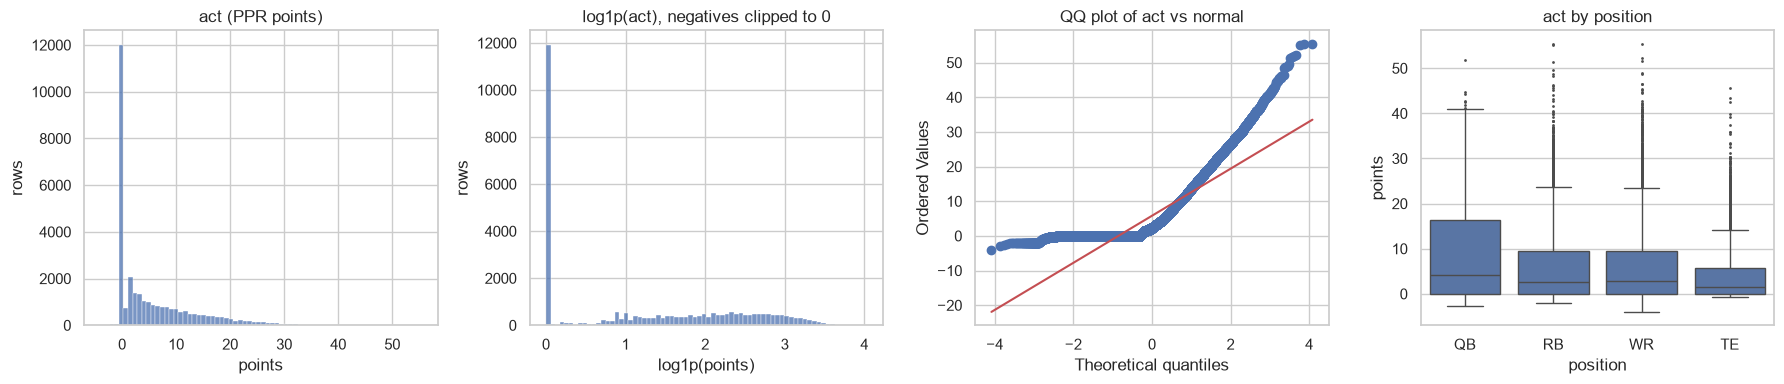

,count,mean,std,min,10%,50%,90%,max
position,,,,,,,,
QB,4282.000,8.585,9.908,-2.600,0.000,4.120,23.220,51.880
RB,8037.000,5.941,7.706,-2.100,0.000,2.600,17.400,55.400
TE,7062.000,3.750,5.532,-0.600,0.000,1.500,11.300,45.600
WR,11888.000,5.919,7.516,-4.000,0.000,2.900,16.800,55.400


In [8]:
t = df[TARGET]
print(f"mean {t.mean():.2f}, median {t.median():.2f}, std {t.std():.2f}, skew {t.skew():.2f}, "
      f"zeros {(t == 0).mean():.2%}, < 1 point {(t < 1).mean():.2%}, p99 {t.quantile(.99):.1f}, max {t.max():.1f}")
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.histplot(t, bins=70, ax=axes[0]); axes[0].set(title="act (PPR points)", xlabel="points", ylabel="rows")
sns.histplot(np.log1p(t.clip(lower=0)), bins=70, ax=axes[1]); axes[1].set(title="log1p(act), negatives clipped to 0", xlabel="log1p(points)", ylabel="rows")
stats.probplot(t, dist="norm", plot=axes[2]); axes[2].set(title="QQ plot of act vs normal")
sns.boxplot(df, x="position", y=TARGET, ax=axes[3], order=["QB", "RB", "WR", "TE"], fliersize=1)
axes[3].set(title="act by position", ylabel="points")
savefig("target_distribution")
df.groupby("position")[TARGET].describe(percentiles=[.1, .5, .9])

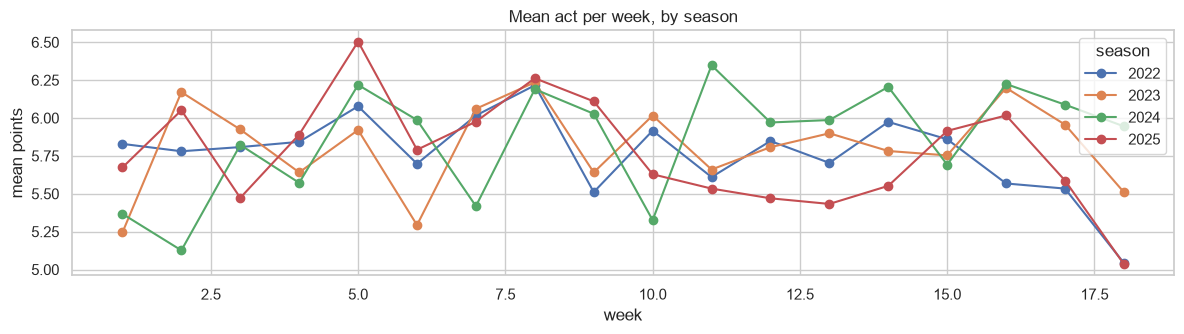

        mean  median   std
season                    
2022   5.766   2.300 7.633
2023   5.816   2.400 7.653
2024   5.854   2.200 7.806
2025   5.764   2.400 7.660


In [9]:
ts = df.groupby(["season", "week"])[TARGET].mean().reset_index()
fig, ax = plt.subplots(figsize=(12, 3.5))
for s, g in ts.groupby("season"):
    ax.plot(g.week, g[TARGET], "o-", label=s)
ax.set(title="Mean act per week, by season", xlabel="week", ylabel="mean points"); ax.legend(title="season")
savefig("target_over_time")
print(df.groupby("season")[TARGET].agg(["mean", "median", "std"]))

**Findings**


- `act`: mean 5.80, median 2.30, SD 7.69, skew 1.61, max 55.4. **37.2% exactly 0** (it was 22.8% in Sleeper's universe). The rows now include about 13% players who end up not playing, plus backups who play but don't score. That is a strongly zero-inflated, right-skewed target.
- By position, medians are QB 4.1 (backup QBs are now included), RB 2.6, WR 2.9, TE 1.5.
- No trend across seasons (means 5.76-5.85).
- **Implications:** no log transform (it can't take the negatives, and lineups need expected points, i.e. a mean). Use squared-error loss with RMSE as the primary metric. **Tweedie** is now a serious candidate because of the 37% zero mass, and the evaluation should also report played-only rows.

## 5. Missing values
Disguised nulls first, then per-column missingness, co-occurrence, mechanism (MCAR test, MAR via a classifier
on the missing indicator, MNAR by domain logic) and missingness vs. target.

[{'column': 'practice_status', 'values': ['\n    '], 'n': 26}]


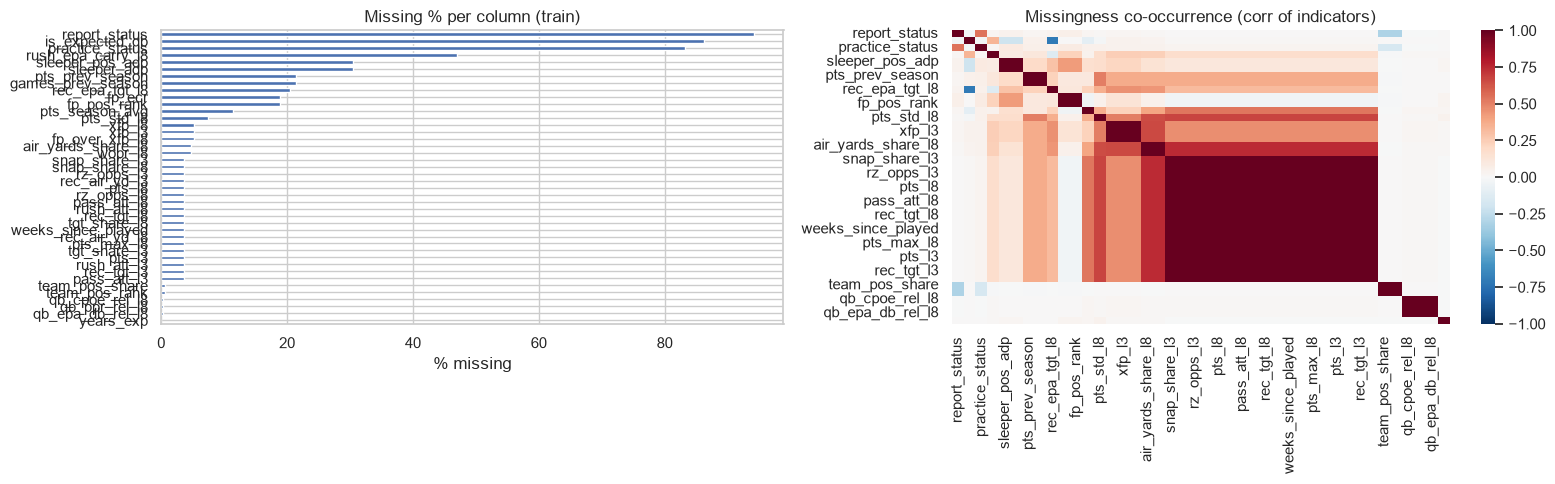

report_status        94.170
is_expected_qb       86.310
practice_status      83.260
rush_epa_carry_l8    46.940
sleeper_pos_adp      30.410
sleeper_adp          30.410
pts_prev_season      21.410
games_prev_season    21.410
rec_epa_tgt_l8       20.440
fp_ecr               18.880
fp_pos_rank          18.880
pts_season_avg       11.380
pts_std_l8            7.500
xfp_l8                5.170
xfp_l3                5.170
fp_over_xfp_l8        5.170
air_yards_share_l8    4.700
wopr_l8               4.700
snap_share_l3         3.590
snap_share_l8         3.590
rz_opps_l3            3.570
rec_air_yd_l3         3.570
pts_l8                3.570
rz_opps_l8            3.570
pass_att_l8           3.570
rush_att_l8           3.570
rec_tgt_l8            3.570
tgt_share_l8          3.570
weeks_since_played    3.570
rec_air_yd_l8         3.570
pts_max_l8            3.570
tgt_share_l3          3.570
pts_l3                3.570
rush_att_l3           3.570
rec_tgt_l3            3.570
pass_att_l3         

In [10]:
NULL_TOKENS = ["NA", "N/A", "null", "None", "", " ", "?", "-"]  # compared after stripping whitespace
def apply_null_tokens(frame, log=None):
    out = []
    for c in frame.select_dtypes(["object", "string"]).columns:
        stripped = frame[c].astype("string").str.strip()
        mask = frame[c].notna() & stripped.isin(NULL_TOKENS)
        if mask.any():
            out.append({"column": c, "values": sorted(frame.loc[mask, c].unique().tolist()), "n": int(mask.sum())})
            frame.loc[mask, c] = np.nan
            if log is not None:
                log.append(("null_tokens", c, int(mask.sum()), "disguised null -> NaN"))
    return out

print(apply_null_tokens(df, cleaning_log))
miss = df.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
miss.plot.barh(ax=axes[0]); axes[0].invert_yaxis(); axes[0].set(title="Missing % per column (train)", xlabel="% missing", ylabel="")
co = df[miss.index].isna().astype(int).corr()
sns.heatmap(co, cmap="RdBu_r", center=0, ax=axes[1], vmin=-1, vmax=1); axes[1].set(title="Missingness co-occurrence (corr of indicators)")
savefig("missingness")
miss.round(2)

In [11]:
def littles_mcar(data: pd.DataFrame):
    # Little (1988) chi-square test with ML (pairwise-complete) estimates of mean and covariance.
    x = data.to_numpy(float)
    mu, cov = np.nanmean(x, axis=0), data.cov().to_numpy()
    pattern = pd.Series(map(tuple, np.isnan(x))).astype(str)
    d2, dof = 0.0, 0
    for _, idx in pattern.groupby(pattern).groups.items():
        sub = x[idx]
        obs = ~np.isnan(sub[0])
        if obs.sum() == 0:
            continue
        diff = np.nanmean(sub[:, obs], axis=0) - mu[obs]
        d2 += len(idx) * diff @ np.linalg.pinv(cov[np.ix_(obs, obs)]) @ diff
        dof += obs.sum()
    dof -= x.shape[1]
    return d2, dof, stats.chi2.sf(d2, dof)

mcar_cols = ["pts_l3", "pts_season_avg", "pts_prev_season", "xfp_l8", "pts_std_l8", "fp_ecr", "age"]
d2, dof, p = littles_mcar(df[mcar_cols])
print(f"Little's MCAR test on {mcar_cols}: chi2={d2:.0f}, dof={dof}, p={p:.2g}")

# MAR: can observed columns predict where a column is missing?
pred_cols = [c for c in CONT + LOWCARD if df[c].isna().mean() == 0 and c != TARGET]
X_obs = df[pred_cols]
mar = []
for c in miss.index:
    y = df[c].isna().astype(int)
    if y.mean() < 0.005:
        continue
    # shuffled folds: rows are time-ordered, and unshuffled folds would measure drift, not missingness
    cv = StratifiedKFold(3, shuffle=True, random_state=SEED)
    auc = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=SEED), X_obs, y, cv=cv, scoring="roc_auc").mean()
    top = pd.Series(DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(X_obs, y).feature_importances_, pred_cols).idxmax()
    tgt_miss, tgt_obs = df.loc[y == 1, TARGET].mean(), df.loc[y == 0, TARGET].mean()
    u = stats.mannwhitneyu(df.loc[y == 1, TARGET], df.loc[y == 0, TARGET])
    rb = 1 - 2 * u.statistic / (y.sum() * (len(y) - y.sum()))
    mar.append({"column": c, "missing_pct": 100 * y.mean(), "mar_auc": auc, "top_predictor": top,
                "act_if_missing": tgt_miss, "act_if_present": tgt_obs, "rank_biserial": rb, "p": u.pvalue})
mar = pd.DataFrame(mar)
mar["p_bh"] = multipletests(mar.p, method="fdr_bh")[1]
mar

Little's MCAR test on ['pts_l3', 'pts_season_avg', 'pts_prev_season', 'xfp_l8', 'pts_std_l8', 'fp_ecr', 'age']: chi2=16789, dof=133, p=0


,column,missing_pct,mar_auc,top_predictor,act_if_missing,act_if_present,rank_biserial,p,p_bh
0,report_status,94.167,0.555,vacated_pts,5.883,4.460,-0.144,0.000,0.000
1,is_expected_qb,86.306,0.730,age,5.358,8.585,0.096,0.000,0.000
2,practice_status,83.261,0.593,age,5.527,7.158,0.119,0.000,0.000
3,rush_epa_carry_l8,46.944,0.552,age,3.931,7.454,0.251,0.000,0.000
4,sleeper_pos_adp,30.414,0.805,week,2.307,7.327,0.456,0.000,0.000
5,sleeper_adp,30.414,0.805,week,2.307,7.327,0.456,0.000,0.000
6,pts_prev_season,21.408,0.852,age,3.805,6.344,0.204,0.000,0.000
7,games_prev_season,21.408,0.852,age,3.805,6.344,0.204,0.000,0.000
8,rec_epa_tgt_l8,20.442,0.740,games_season,5.709,5.823,0.142,0.000,0.000
9,fp_ecr,18.878,0.656,age,1.427,6.818,0.487,0.000,0.000


**Findings**


- `practice_status` whitespace (26 rows) becomes NaN. `report_status` is NaN when the player is not on the report (94.2%).
- **Structural (MNAR by design):** `report_status`/`practice_status` mean "not listed". They get their own level, not imputation. `report_status` levels behave very differently: Doubtful 183 rows with 0.5% played (mean 0.02 points), Questionable 1,639 rows with 68% played (4.9), not listed 89% played (5.9).
- **Yearly rankings:** `fp_ecr` is missing for 18.9% of rows (unranked by FantasyPros, 1.4 points against 6.8), and `sleeper_adp` for 30.4% (undrafted, 2.3 against 7.3). The fact of being unranked is informative, so a missing indicator is needed.
- **History block (3.6%):** all `*_l3`/`*_l8` columns go missing together for players with no earlier game since 2021. MAR: predicted from `games_season`/age with AUC 0.99. These rows score 1.6 against 6.0. Indicator recommended. `xfp_*` is missing for 5.2% (no ff_opportunity history, 1.0 against 6.1).
- `pts_prev_season` is missing for 21.4% (rookies and players absent last season; MAR, 3.8 against 6.3). An indicator is recommended.
- `pts_season_avg` is missing for 11.4%, **exactly when `games_season == 0`** (AUC 1.00). An indicator would duplicate `games_season`, so none is added.
- Little's test rejects MCAR (chi2 16,789, dof 133), as expected, because missingness follows from career stage.

## 6. Numeric distributions
Summary statistics for every continuous column, histograms for the main ones (axis clipped to the 1st-99th
percentile when the tail compresses the view; statistics use all rows), skew, and IQR / robust-z outlier counts.

In [12]:
summ = df[CONT].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
summ["skew"] = df[CONT].skew()
q1, q3 = df[CONT].quantile(.25), df[CONT].quantile(.75)
iqr = q3 - q1
summ["iqr_outliers"] = ((df[CONT] < q1 - 1.5 * iqr) | (df[CONT] > q3 + 1.5 * iqr)).sum()
med = df[CONT].median()
mad = (df[CONT] - med).abs().median()
summ["mad_outliers"] = (((df[CONT] - med).abs() / (1.4826 * mad.replace(0, np.nan))) > 3.5).sum()
summ[["count", "mean", "std", "min", "1%", "50%", "99%", "max", "skew", "iqr_outliers", "mad_outliers"]]

,count,mean,std,min,1%,50%,99%,max,skew,iqr_outliers,mad_outliers
total_line,31269.000,44.080,4.244,28.500,34.000,44.000,54.000,56.500,-0.023,249,0
team_spread,31269.000,0.038,6.067,-19.500,-14.000,1.000,14.000,19.500,0.006,482,0
implied_total,31269.000,22.059,3.701,10.500,13.750,22.000,30.250,32.250,-0.003,37,0
age,31269.000,26.634,3.233,20.638,21.615,26.018,37.206,45.432,1.153,721,409
years_exp,31265.000,3.640,3.223,0.000,0.000,3.000,14.000,22.000,1.227,376,376
pts_l3,30152.000,6.584,6.558,-2.000,-0.067,4.567,25.620,40.527,1.063,358,293
snap_share_l3,30148.000,0.462,0.305,0.000,0.000,0.439,1.000,1.005,0.181,0,0
tgt_share_l3,30152.000,0.075,0.084,0.000,0.000,0.044,0.328,0.476,1.251,602,1024
rec_tgt_l3,30152.000,2.350,2.698,0.000,0.000,1.333,10.667,18.000,1.363,828,1379
rush_att_l3,30152.000,2.158,4.272,0.000,0.000,0.000,19.000,31.667,2.548,4259,0


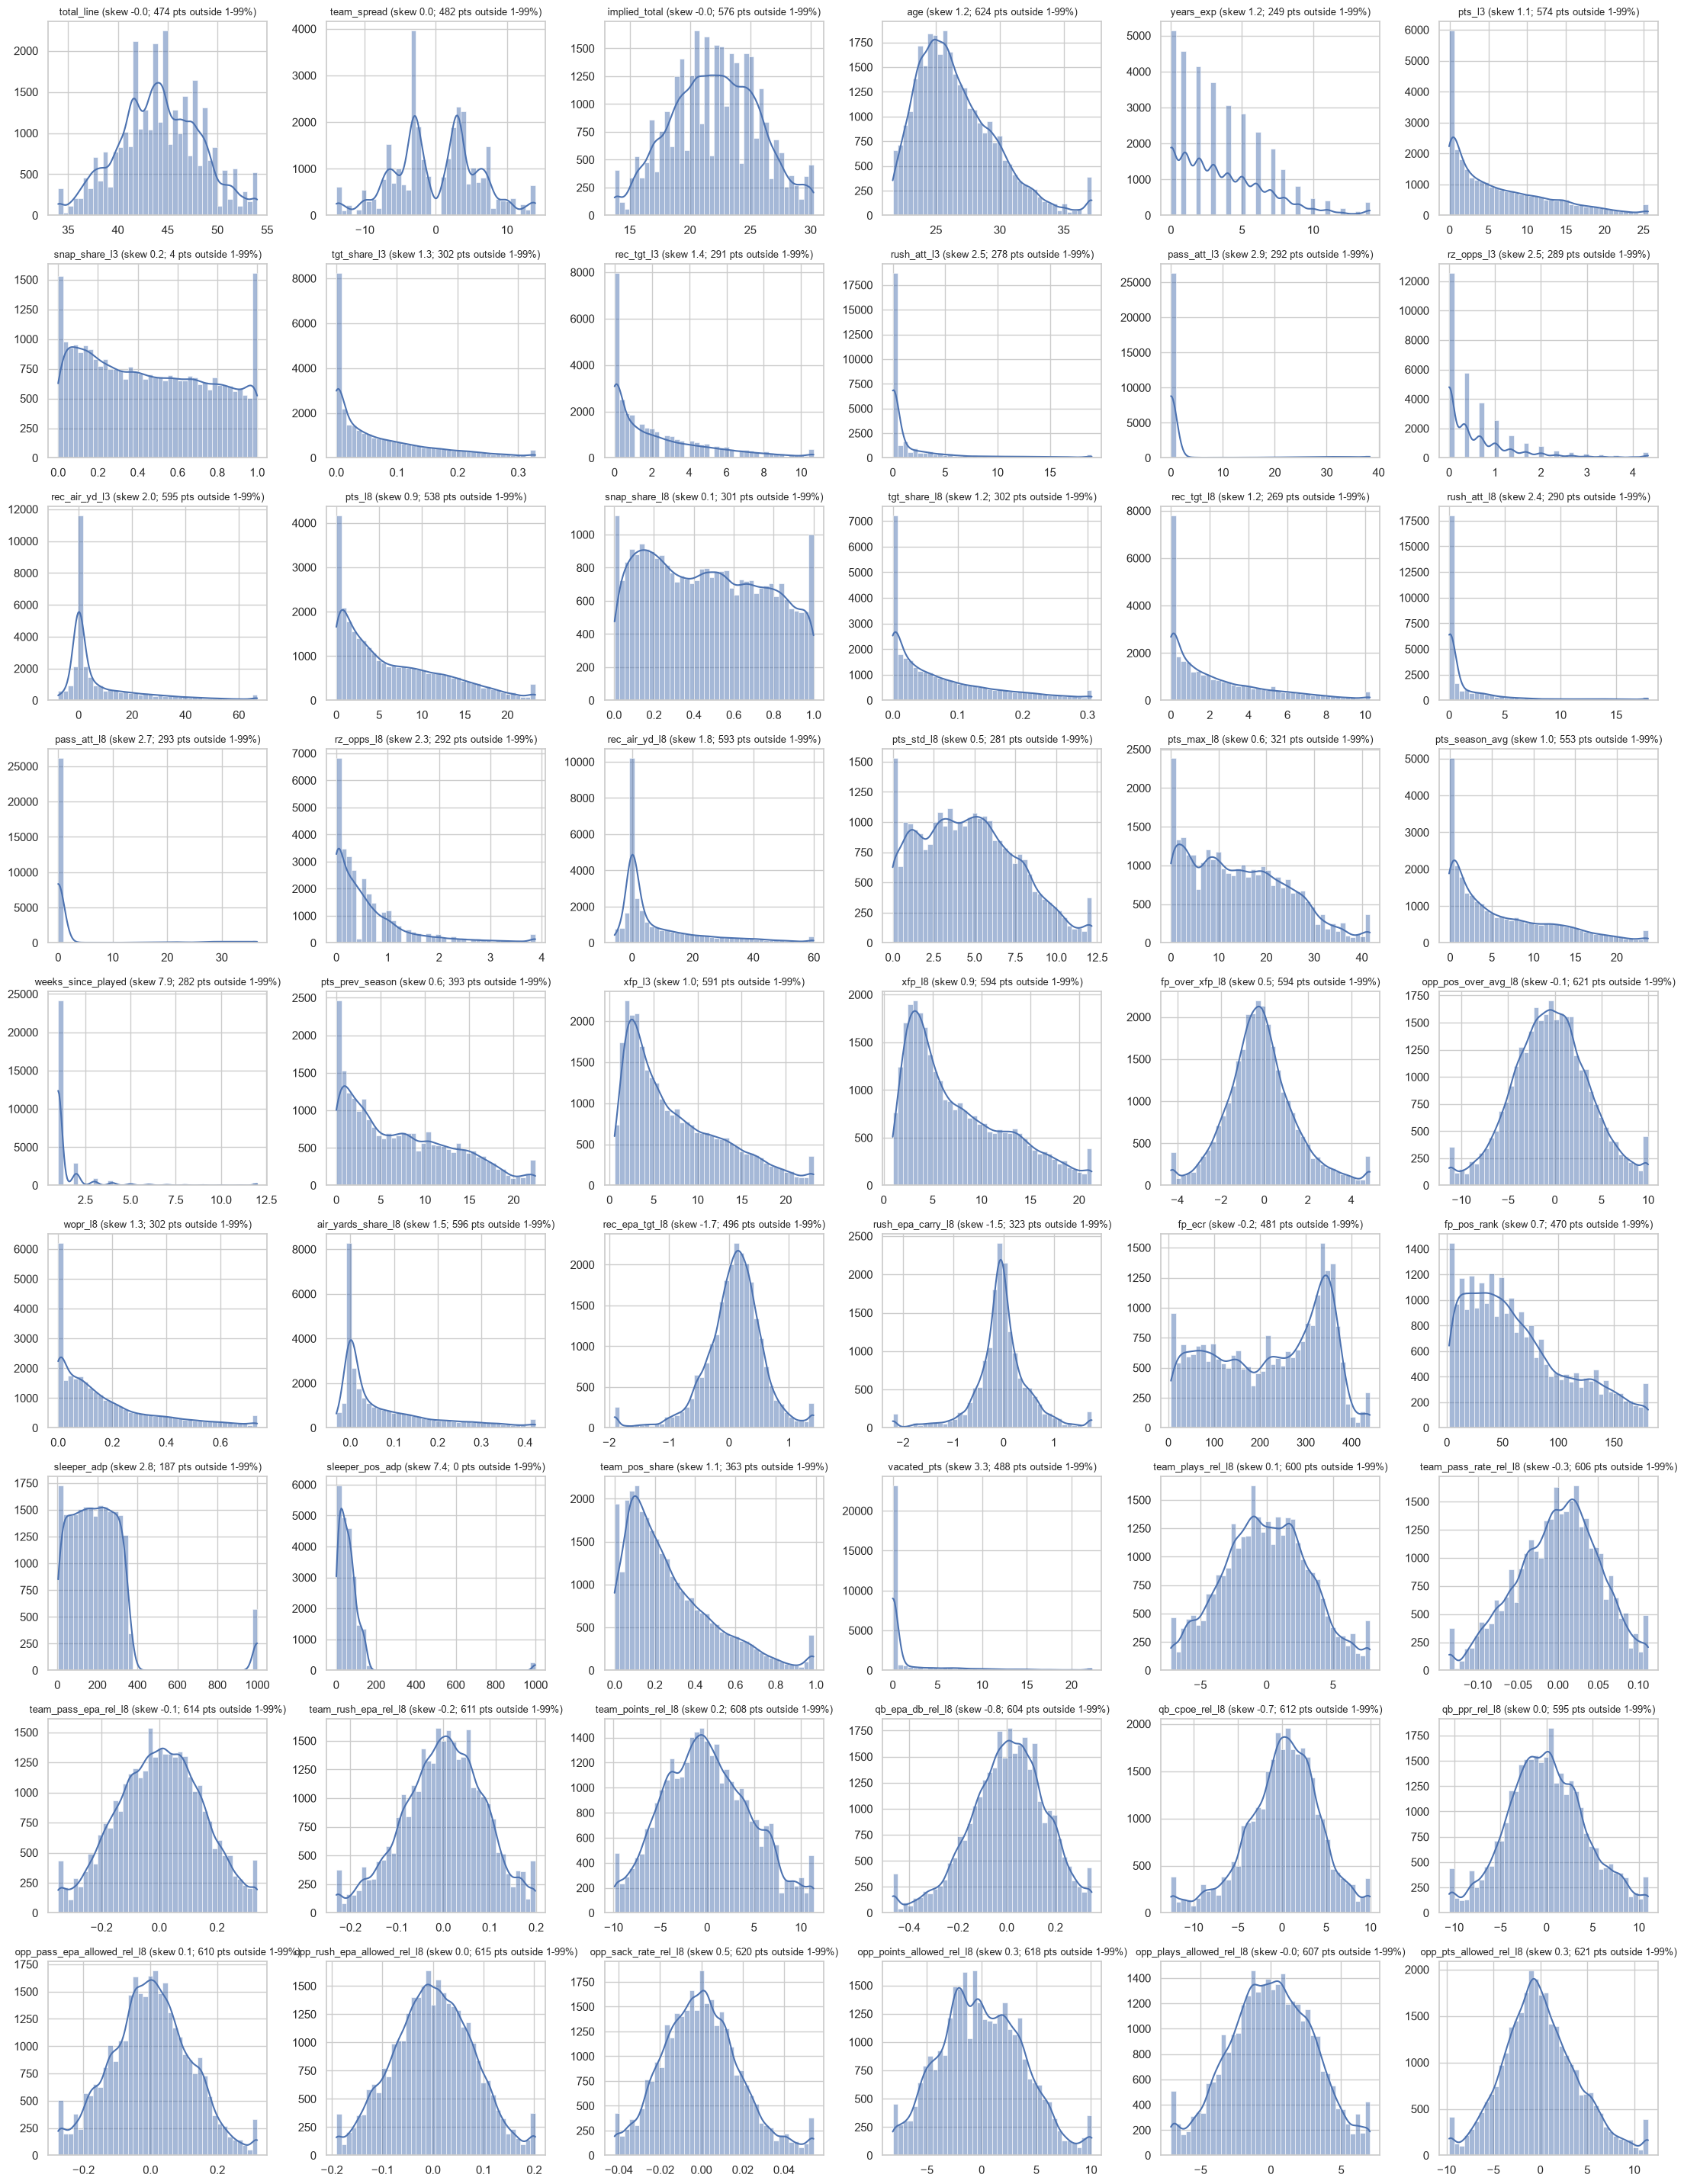

In [13]:
show = [c for c in CONT if c != TARGET]
n = len(show); ncols = 6; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(22, 3.2 * nrows))
for ax, c in zip(axes.flat, show):
    s = df[c].dropna()
    lo, hi = s.quantile([.01, .99])
    hidden = ((s < lo) | (s > hi)).sum()
    sns.histplot(s.clip(lo, hi), bins=40, kde=True, ax=ax)
    ax.set(title=f"{c} (skew {s.skew():.1f}; {hidden} pts outside 1-99%)", xlabel="", ylabel="")
    ax.title.set_size(9)
for ax in axes.flat[n:]:
    ax.remove()
savefig("numeric_distributions")

|skew| > 1: ['age', 'years_exp', 'pts_l3', 'tgt_share_l3', 'rec_tgt_l3', 'rush_att_l3', 'pass_att_l3', 'rz_opps_l3', 'rec_air_yd_l3', 'tgt_share_l8', 'rec_tgt_l8', 'rush_att_l8', 'pass_att_l8', 'rz_opps_l8', 'rec_air_yd_l8', 'pts_season_avg', 'weeks_since_played', 'wopr_l8', 'air_yards_share_l8', 'rec_epa_tgt_l8', 'rush_epa_carry_l8', 'sleeper_adp', 'sleeper_pos_adp', 'team_pos_share', 'vacated_pts']


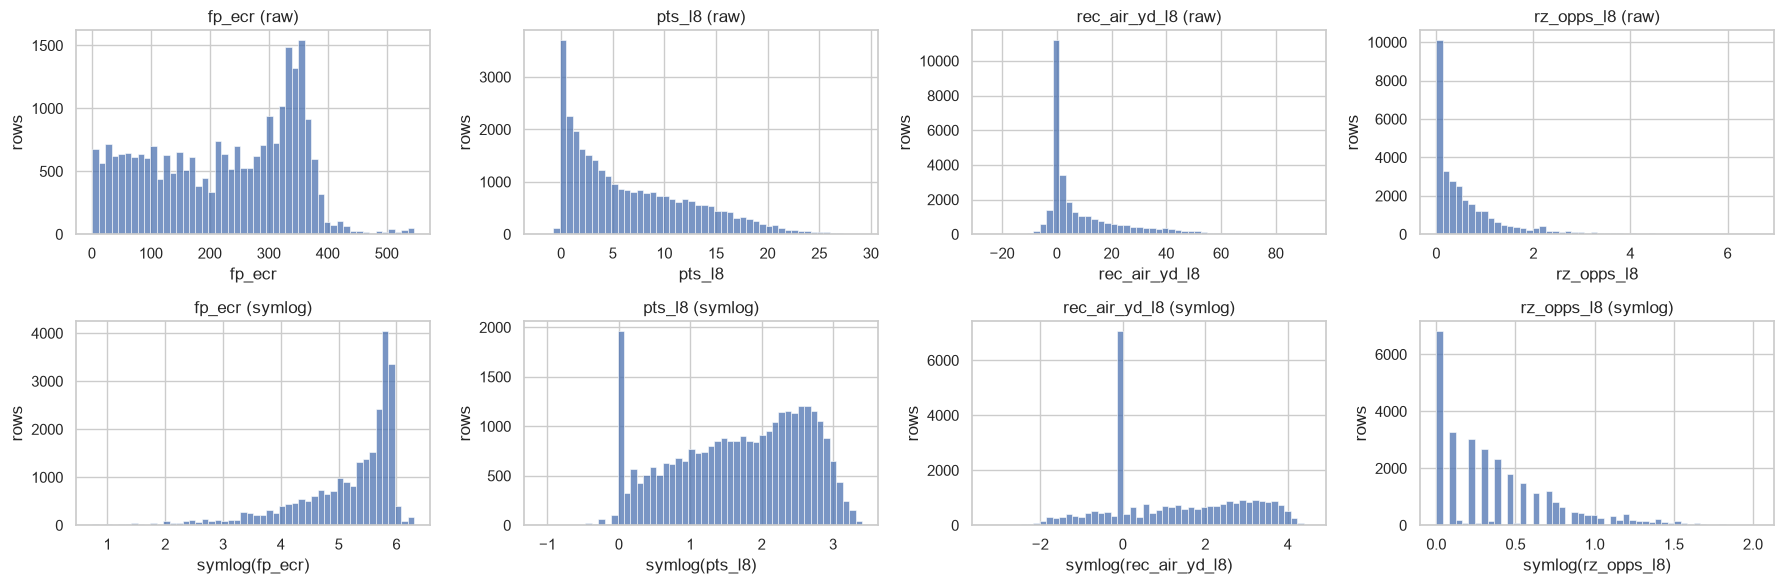

In [14]:
skewed = summ.index[summ["skew"].abs() > 1].tolist()
print("|skew| > 1:", skewed)
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for i, c in enumerate(["fp_ecr", "pts_l8", "rec_air_yd_l8", "rz_opps_l8"]):
    s = df[c].dropna()
    sns.histplot(s, bins=50, ax=axes[0, i]); axes[0, i].set(title=f"{c} (raw)", xlabel=c, ylabel="rows")
    sns.histplot(np.sign(s) * np.log1p(s.abs()), bins=50, ax=axes[1, i]); axes[1, i].set(title=f"{c} (symlog)", xlabel=f"symlog({c})", ylabel="rows")
savefig("skewed_log_views")

**Findings**


- 19 continuous columns have |skew| > 1. They are position-structured zeros (`pass_att_*` 0 for non-QBs, `rush_att_*` near 0 for WR/TE), or the long tails of `weeks_since_played` (players back from long injuries, up to 44 weeks) and of ADP. They are not errors. Nothing is removed and nothing capped.
- `fp_ecr` runs 1-546 and `sleeper_adp` 1-~600 (preseason ranks). Both are bounded and only ranks, so a tree needs no transform.
- `fp_over_xfp_l8` (efficiency) centers near -0.16 with a range of -16 to +16, which is the right shape for points over expectation.

## 7. Categorical and low-cardinality columns
Spelling consistency (fuzzy matching), counts, rare and dominant levels.

team: 32 levels; fuzzy near-duplicates (ratio >= 90): []
position: 4 levels; fuzzy near-duplicates (ratio >= 90): []
roof: 4 levels; fuzzy near-duplicates (ratio >= 90): []
opponent: 32 levels; fuzzy near-duplicates (ratio >= 90): []
report_status: 3 levels; fuzzy near-duplicates (ratio >= 90): []
practice_status: 3 levels; fuzzy near-duplicates (ratio >= 90): []


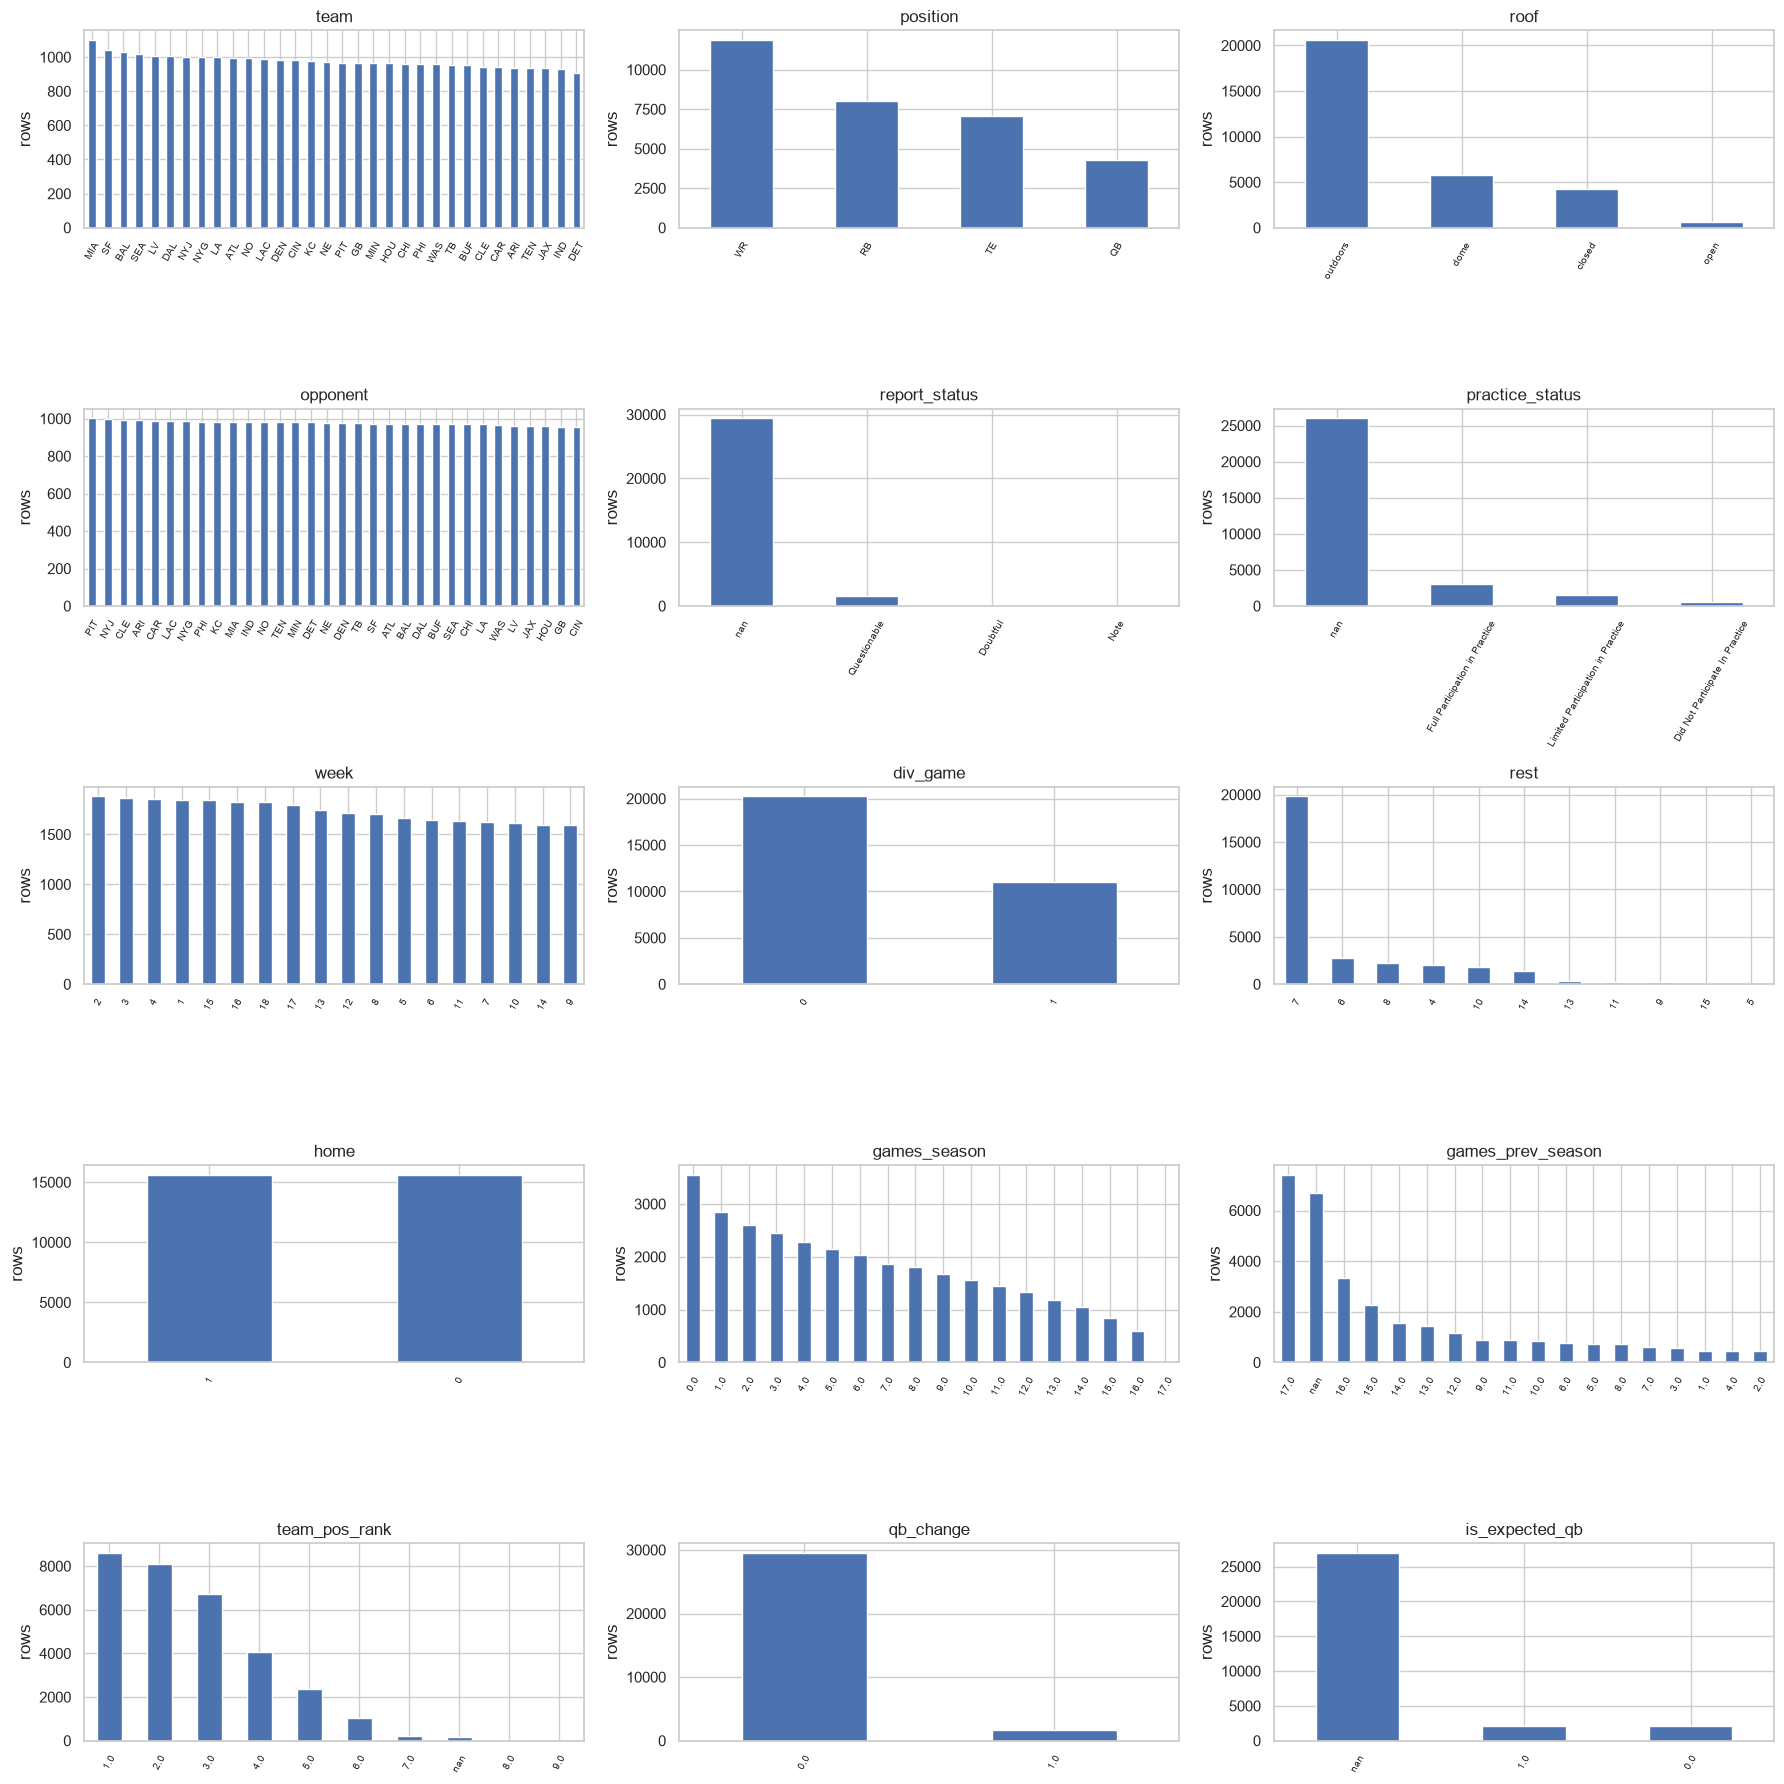

rare levels: {'report_status': ['Doubtful', 'Note'], 'rest': [13, 11, 9, 15, 5], 'games_season': [17.0], 'team_pos_rank': [7.0, nan, 8.0, 9.0]}
dominant levels (>= 90%): {'report_status': (nan, np.float64(94.2)), 'qb_change': (np.float64(0.0), np.float64(94.5))}


In [15]:
for c in CAT:
    levels = df[c].dropna().astype(str).unique()
    near = [(a, b, fuzz.ratio(a.lower(), b.lower())) for i, a in enumerate(levels) for b in levels[i + 1:]
            if fuzz.ratio(a.lower(), b.lower()) >= 90]
    print(f"{c}: {len(levels)} levels; fuzzy near-duplicates (ratio >= 90): {near}")
show_cat = CAT + [c for c in LOWCARD if c not in ("season",)]
fig, axes = plt.subplots(int(np.ceil(len(show_cat) / 3)), 3, figsize=(18, 3.6 * int(np.ceil(len(show_cat) / 3))))
rare, dominant = {}, {}
for ax, c in zip(axes.flat, show_cat):
    vc = df[c].value_counts(dropna=False)
    pct = vc / len(df) * 100
    vc.head(32).plot.bar(ax=ax)
    ax.set(title=c, ylabel="rows", xlabel="")
    ax.tick_params(axis="x", rotation=60, labelsize=7)
    r = vc[(pct < 1) | (vc < 30)].index.tolist()
    if r and c not in ("team", "opponent"):
        rare[c] = r
    if pct.iloc[0] >= 90:
        dominant[c] = (vc.index[0], round(pct.iloc[0], 1))
for ax in axes.flat[len(show_cat):]:
    ax.remove()
savefig("categorical_counts")
print("rare levels:", rare)
print("dominant levels (>= 90%):", dominant)

**Findings**


- No spelling variants: team abbreviations are consistent (32), and positions come from rosters.
- **Rare levels:** `report_status` "Doubtful" (183, 0.6%) and "Note" (2). Doubtful is rare by count but **very informative** (0.5% played). **Grouping it would destroy the signal, so it is not grouped.** "Note" is too small to matter.
- **Dominant level:** not on the report, 94.2%.

## 8. Date and time
Coverage per week, gaps, and features whose distribution drifts across seasons.

In [16]:
per_week = df.groupby(["season", "week"]).size().unstack(0)
print("weeks per season:", per_week.notna().sum().to_dict(), "| rows per week: min", per_week.min().min(), "max", per_week.max().max())
print("kickoff range:", df.kickoff.min(), "->", df.kickoff.max())
print("kickoff weekday share:", df.kickoff.dt.day_name().value_counts(normalize=True).round(3).to_dict())
drift = df.groupby("season")[["act", "pts_l8", "xfp_l8", "snap_share_l8", "total_line", "implied_total", "fp_ecr"]].mean()
drift["rows"] = df.groupby("season").size()
drift

weeks per season: {2022: 18, 2023: 18, 2024: 18, 2025: 18} | rows per week: min 367 max 482
kickoff range: 2022-09-08 20:20:00 -> 2026-01-04 20:20:00
kickoff weekday share: {'Sunday': 0.814, 'Monday': 0.075, 'Thursday': 0.072, 'Saturday': 0.034, 'Friday': 0.005, 'Wednesday': 0.002}


,act,pts_l8,xfp_l8,snap_share_l8,total_line,implied_total,fp_ecr,rows
season,,,,,,,,
2022,5.766,6.723,7.741,0.465,44.113,22.079,214.609,7846
2023,5.816,6.645,7.660,0.471,42.996,21.509,216.321,7758
2024,5.854,6.790,7.633,0.474,44.326,22.167,238.036,7876
2025,5.764,6.679,7.609,0.463,44.877,22.476,213.356,7789


**Findings**


- 18 weeks in each of 4 seasons, 367-482 rows per week, no gaps. Kickoffs run from 2022-09-08 to 2026-01-04.
- Feature means are stable across seasons (`act` 5.76-5.85, `xfp_l8` 7.6-7.7, about 7,800 rows per season). `total_line` dips in 2023 (43.0), the league-wide scoring dip.
- `kickoff` is not a feature. The weekday is covered by `rest`.

## 9. Feature-feature relationships (target excluded)
Pearson and Spearman heatmaps, highly correlated pairs, Cramer's V among categoricals, and categorical vs. numeric.

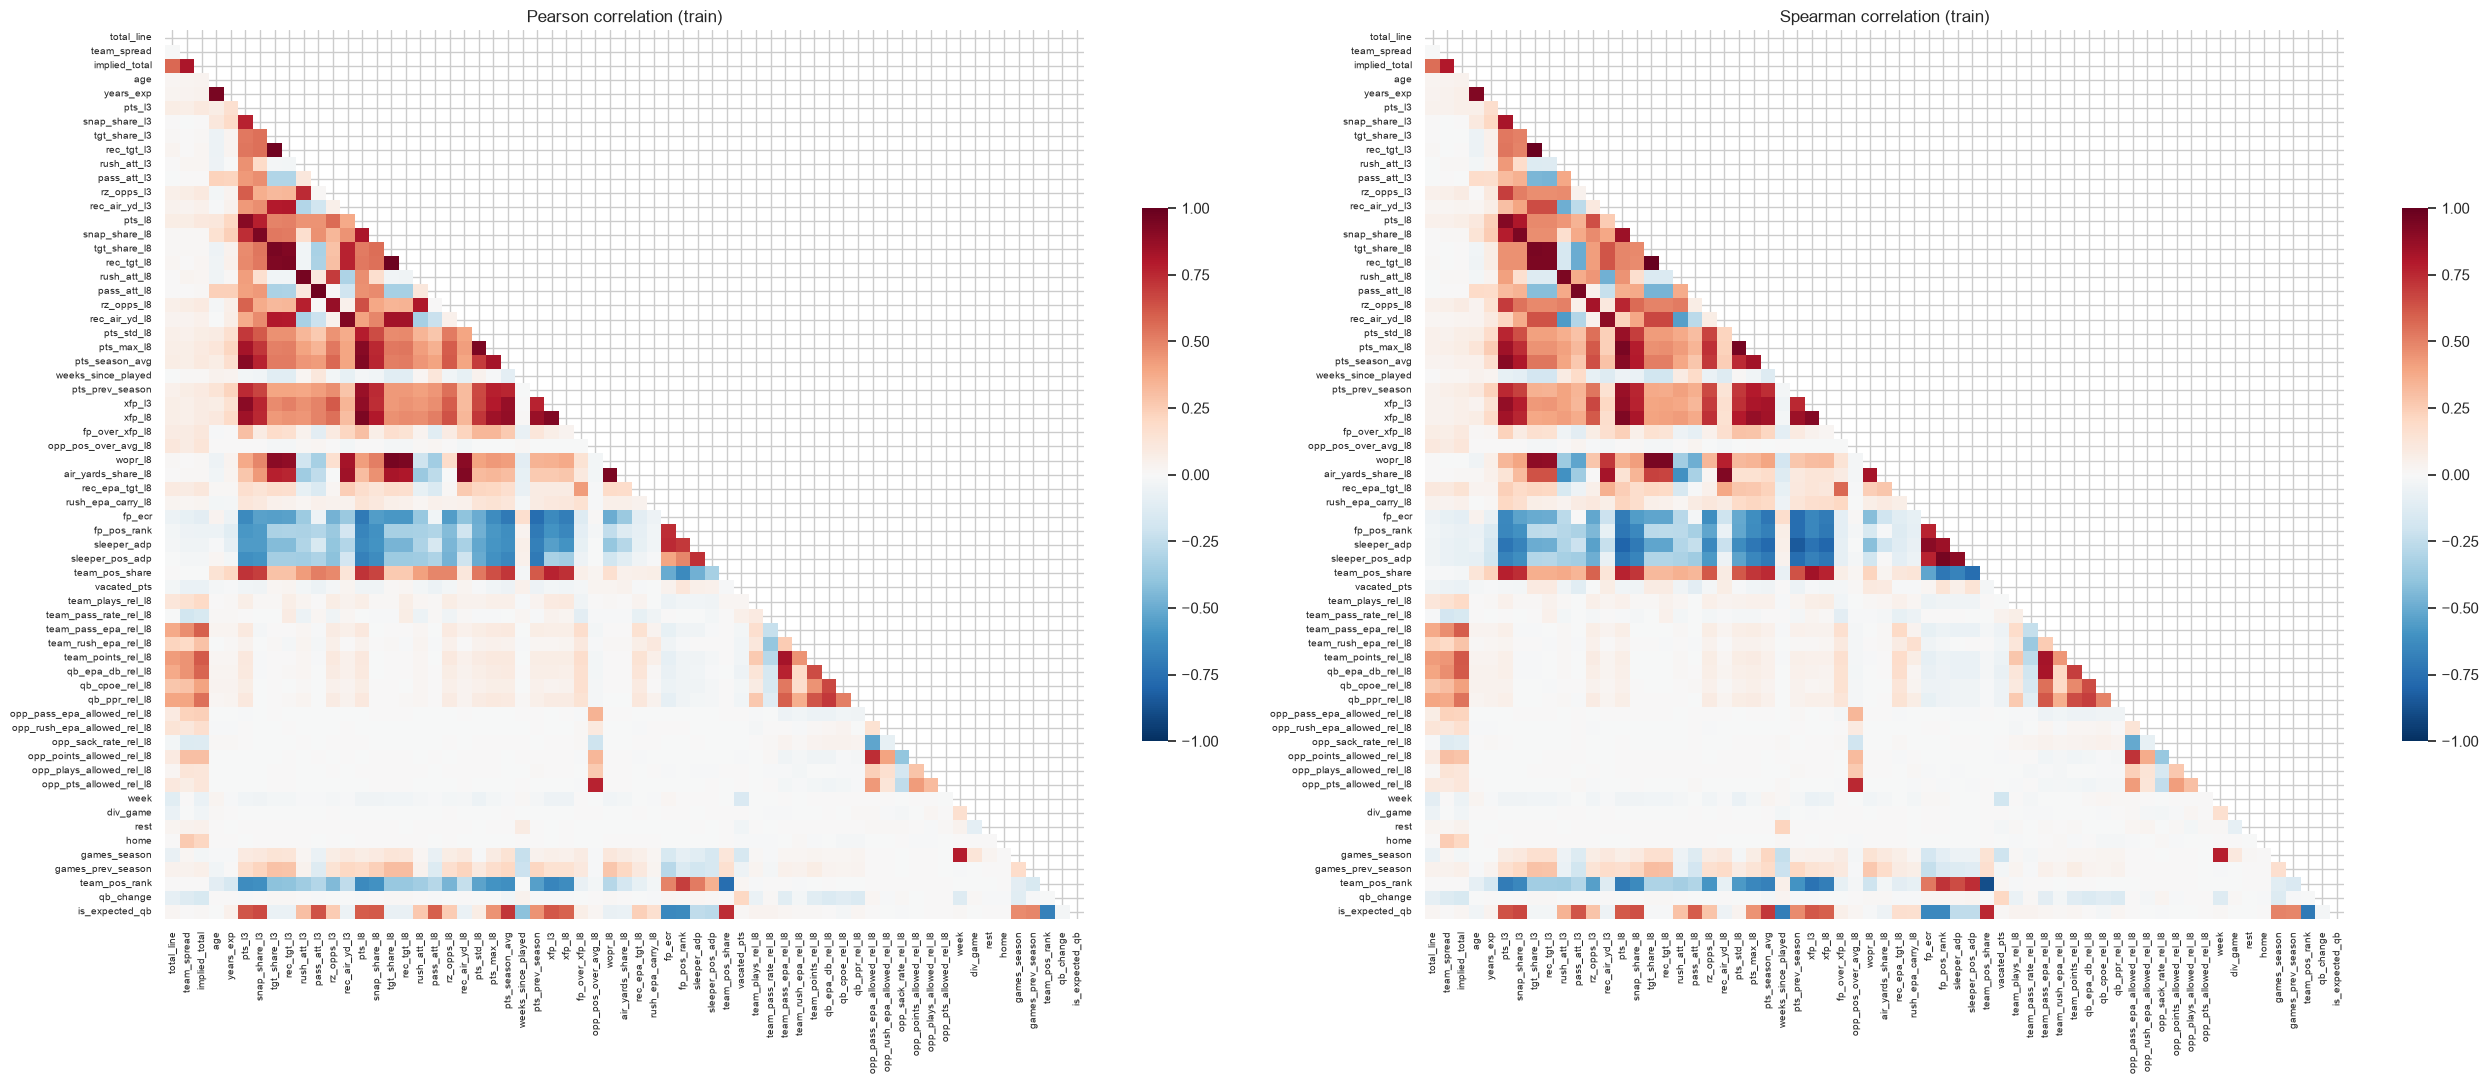

60 pairs with |r| > 0.8; pairs with |pearson - spearman| > 0.2:
                                    pearson  spearman   gap
sleeper_pos_adp fp_pos_rank           0.488     0.955 0.467
team_pos_share  sleeper_pos_adp      -0.334    -0.759 0.425
team_pos_rank   sleeper_pos_adp       0.358     0.739 0.381
sleeper_pos_adp fp_ecr                0.395     0.771 0.376
                xfp_l8               -0.351    -0.726 0.375
                xfp_l3               -0.324    -0.675 0.351
rz_opps_l8      rush_att_l8           0.805     0.517 0.288
is_expected_qb  weeks_since_played   -0.411    -0.690 0.279


,,pearson,spearman,gap
rec_tgt_l8,tgt_share_l8,0.983,0.994,0.011
rec_tgt_l3,tgt_share_l3,0.973,0.992,0.019
pts_max_l8,pts_std_l8,0.943,0.957,0.014
sleeper_pos_adp,fp_pos_rank,0.488,0.955,0.467
wopr_l8,tgt_share_l8,0.959,0.951,0.008
pass_att_l8,pass_att_l3,0.971,0.949,0.022
pts_max_l8,pts_l8,0.913,0.946,0.032
tgt_share_l8,tgt_share_l3,0.947,0.946,0.002
wopr_l8,rec_tgt_l8,0.942,0.945,0.003
rec_tgt_l8,rec_tgt_l3,0.942,0.944,0.002


In [17]:
num = [c for c in CONT + LOWCARD if c not in (TARGET, "season")]
pear, spear = df[num].corr(), df[num].corr(method="spearman")
mask = np.triu(np.ones_like(pear, dtype=bool))
fig, axes = plt.subplots(1, 2, figsize=(26, 11))
for ax, m, name in [(axes[0], pear, "Pearson"), (axes[1], spear, "Spearman")]:
    sns.heatmap(m, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True,
                cbar_kws={"shrink": .6})
    ax.set_title(f"{name} correlation (train)"); ax.tick_params(labelsize=7)
savefig("feature_correlations")
pairs = (pear.where(~mask).stack().rename("pearson").to_frame()
         .join(spear.where(~mask).stack().rename("spearman")))
pairs["gap"] = (pairs.pearson - pairs.spearman).abs()
high = pairs[(pairs.pearson.abs() > .8) | (pairs.spearman.abs() > .8)].sort_values("spearman", key=abs, ascending=False)
print(f"{len(high)} pairs with |r| > 0.8; pairs with |pearson - spearman| > 0.2:")
print(pairs[pairs.gap > .2].sort_values("gap", ascending=False).head(8))
high

In [18]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))

cat_all = [c for c in CAT if df[c].nunique() > 1]
cv = pd.DataFrame([[cramers_v(df[a].fillna("NA"), df[b].fillna("NA")) for b in cat_all] for a in cat_all], cat_all, cat_all)
print(cv.round(2))

rows = []
for c in ["position", "roof", "report_status"]:
    for x in ["fp_ecr", "pts_l8", "snap_share_l8", "age", "xfp_l8"]:
        groups = [g.dropna().to_numpy() for _, g in df.groupby(c)[x]]
        groups = [g for g in groups if len(g) > 0]
        h, p = stats.kruskal(*groups)
        n_ = sum(len(g) for g in groups)
        rows.append({"cat": c, "num": x, "H": h, "eps2": (h - len(groups) + 1) / (n_ - len(groups)), "p": p})
kw = pd.DataFrame(rows); kw["p_bh"] = multipletests(kw.p, method="fdr_bh")[1]
kw.sort_values("eps2", ascending=False).head(10)

                 team  position  roof  opponent  report_status  practice_status
team            1.000     0.050 0.410     0.170          0.060            0.110
position        0.050     1.000 0.010     0.010          0.030            0.040
roof            0.410     0.010 1.000     0.410          0.010            0.020
opponent        0.170     0.010 0.410     1.000          0.040            0.040
report_status   0.060     0.030 0.010     0.040          1.000            0.460
practice_status 0.110     0.040 0.020     0.040          0.460            1.000


,cat,num,H,eps2,p,p_bh
2,position,snap_share_l8,4947.492,0.164,0.000,0.000
4,position,xfp_l8,4448.366,0.150,0.000,0.000
1,position,pts_l8,3849.492,0.128,0.000,0.000
0,position,fp_ecr,1132.015,0.045,0.000,0.000
3,position,age,1174.478,0.037,0.000,0.000
10,report_status,fp_ecr,3.639,0.001,0.162,0.347
8,roof,age,25.016,0.001,0.000,0.000
13,report_status,age,3.181,0.001,0.204,0.367
11,report_status,pts_l8,2.466,0.000,0.291,0.437
6,roof,pts_l8,4.414,0.000,0.220,0.367


**Findings**


- 45 pairs with |r| > 0.8:
  - `rec_tgt_l*` ~ `tgt_share_l*` (0.98-0.99): **drop `rec_tgt_l3`, `rec_tgt_l8`**.
  - `_l3` ~ `_l8` windows (0.92-0.96), `xfp_l8` ~ `pts_l8` (0.95), `pts_max_l8` ~ `pts_std_l8` (0.94), `years_exp` ~ `age` (0.95), `implied_total` ~ `team_spread` (0.82). All kept: different windows and definitions, and harmless for trees.
  - **The two yearly sources agree:** Sleeper ADP and FantasyPros rank have Spearman 0.91 overall and 0.96 within position. Pearson is much lower (0.49) because of the undrafted tail. Both kept: they disagree on exactly the players where a second opinion helps.
- Position drives the volume features (snap share epsilon-squared 0.16, `xfp_l8` 0.15).

## 10. Feature-target relationships
The target is skewed and the relationships are mostly monotonic, so **Spearman** is the main measure;
**mutual information** is added to catch non-monotonic shapes. Categoricals: Kruskal-Wallis with
epsilon-squared, then Dunn's post-hoc (BH). Rows repeat per player, so p-values are optimistic; the
effect sizes are what to read.

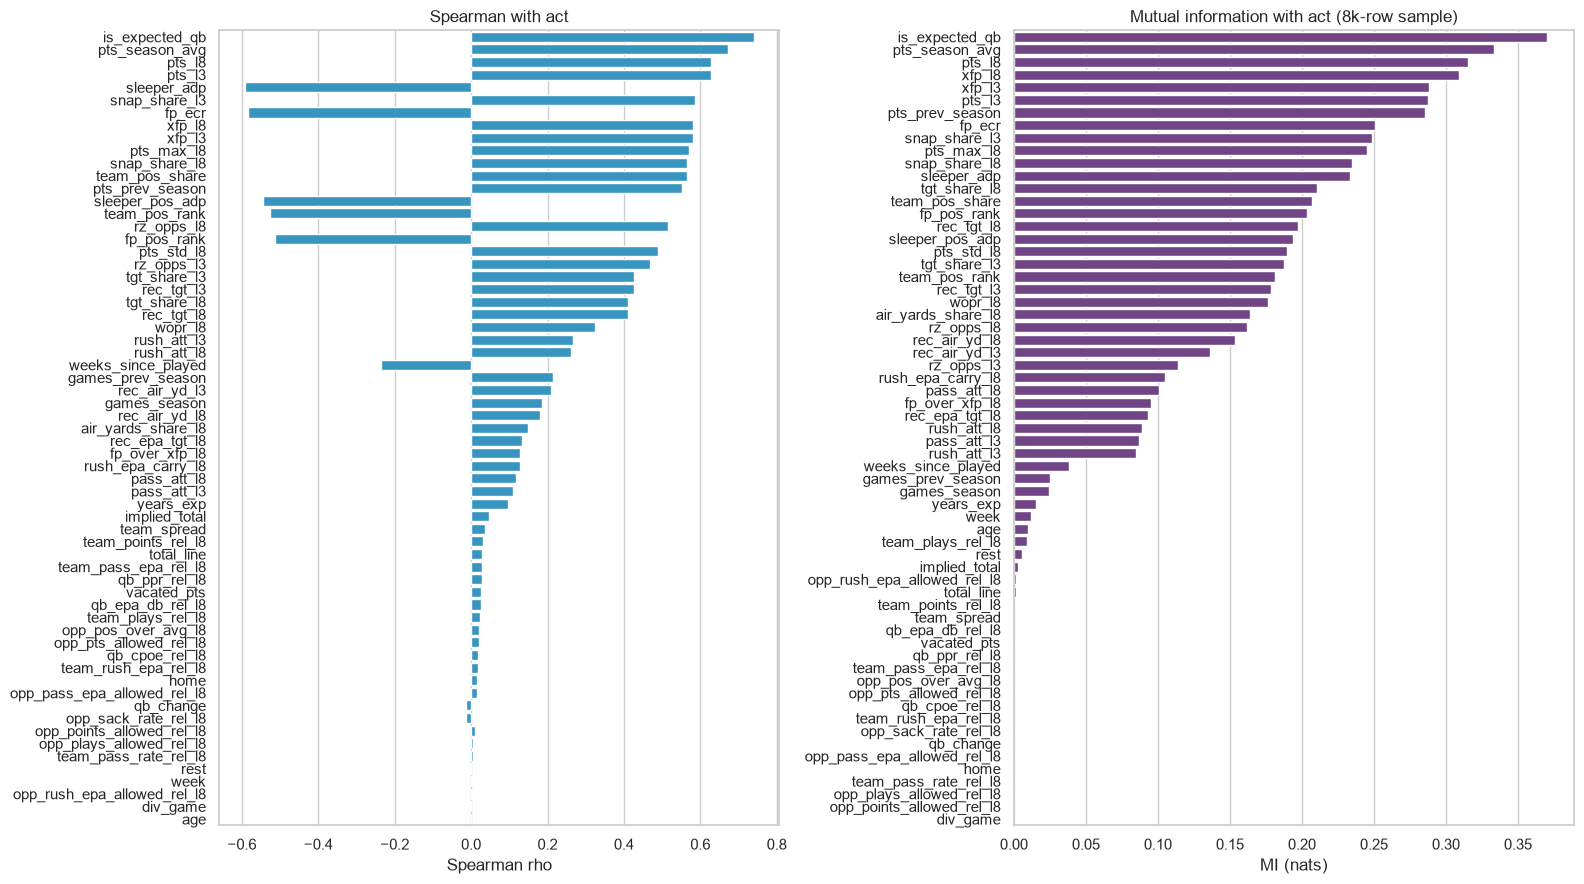

,feature,spearman_target,mi_target,n
62,is_expected_qb,0.740,0.370,4282
23,pts_season_avg,0.671,0.334,27712
13,pts_l8,0.628,0.315,30152
5,pts_l3,0.628,0.287,30152
36,sleeper_adp,-0.593,0.234,21759
...,...,...,...,...
56,rest,-0.003,0.005,31269
54,week,0.002,0.012,31269
49,opp_rush_epa_allowed_rel_l8,0.002,0.002,31269
55,div_game,-0.002,0.000,31269


In [19]:
feat_num = [c for c in num]
sample = df.sample(8000, random_state=SEED)
rows = []
for c in feat_num:
    ok = df[c].notna()
    r_t = stats.spearmanr(df.loc[ok, c], df.loc[ok, TARGET])[0]
    s_ok = sample[c].notna()
    mi = mutual_info_regression(sample.loc[s_ok, [c]], sample.loc[s_ok, TARGET], random_state=SEED)[0]
    rows.append({"feature": c, "spearman_target": r_t, "mi_target": mi, "n": int(ok.sum())})
ft = pd.DataFrame(rows).sort_values("spearman_target", key=abs, ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 9))
sns.barplot(ft, y="feature", x="spearman_target", ax=axes[0], color="#209dd7")
axes[0].set(title="Spearman with act", xlabel="Spearman rho", ylabel="")
ft2 = ft.sort_values("mi_target", ascending=False)
sns.barplot(ft2, y="feature", x="mi_target", ax=axes[1], color="#753991")
axes[1].set(title="Mutual information with act (8k-row sample)", xlabel="MI (nats)", ylabel="")
savefig("feature_target_ranking")
ft.round(3)

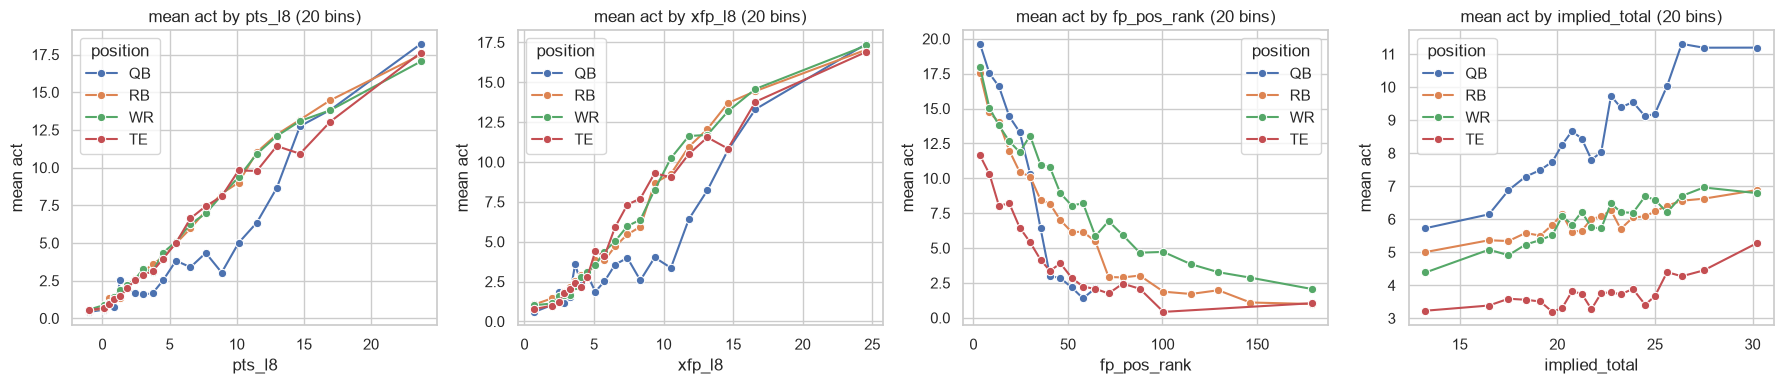

In [20]:
top = ["pts_l8", "xfp_l8", "fp_pos_rank", "implied_total"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, top):
    b = df.assign(bin=pd.qcut(df[c], 20, duplicates="drop")).groupby(["bin", "position"], observed=True)[TARGET].mean().reset_index()
    b["x"] = b.bin.apply(lambda iv: iv.mid)
    sns.lineplot(b, x="x", y=TARGET, hue="position", marker="o", ax=ax, hue_order=["QB", "RB", "WR", "TE"])
    ax.set(title=f"mean act by {c} (20 bins)", xlabel=c, ylabel="mean act")
savefig("binned_means_top_features")

In [21]:
cat_rows = []
for c in ["position", "roof", "report_status", "practice_status", "team", "opponent"]:
    d_ = df[[c, TARGET]].dropna()
    groups = [g[TARGET].to_numpy() for _, g in d_.groupby(c)]
    h, p = stats.kruskal(*groups)
    eps2 = (h - len(groups) + 1) / (len(d_) - len(groups))
    cat_rows.append({"feature": c, "levels": len(groups), "eps2_target": eps2, "p": p})
cat_t = pd.DataFrame(cat_rows)
cat_t["p_bh"] = multipletests(cat_t.p, method="fdr_bh")[1]
print(cat_t.round(4))
print("Dunn post-hoc (BH) of act across report_status:")
sp.posthoc_dunn(df.dropna(subset=["report_status"]), val_col=TARGET, group_col="report_status", p_adjust="fdr_bh").round(4)

           feature  levels  eps2_target     p  p_bh
0         position       4        0.016 0.000 0.000
1             roof       4        0.000 0.218 0.262
2    report_status       3        0.082 0.000 0.000
3  practice_status       3        0.035 0.000 0.000
4             team      32        0.004 0.000 0.000
5         opponent      32        0.000 0.419 0.419
Dunn post-hoc (BH) of act across report_status:


,Doubtful,Note,Questionable
Doubtful,1.000,0.011,0.000
Note,0.011,1.000,0.178
Questionable,0.000,0.178,1.000


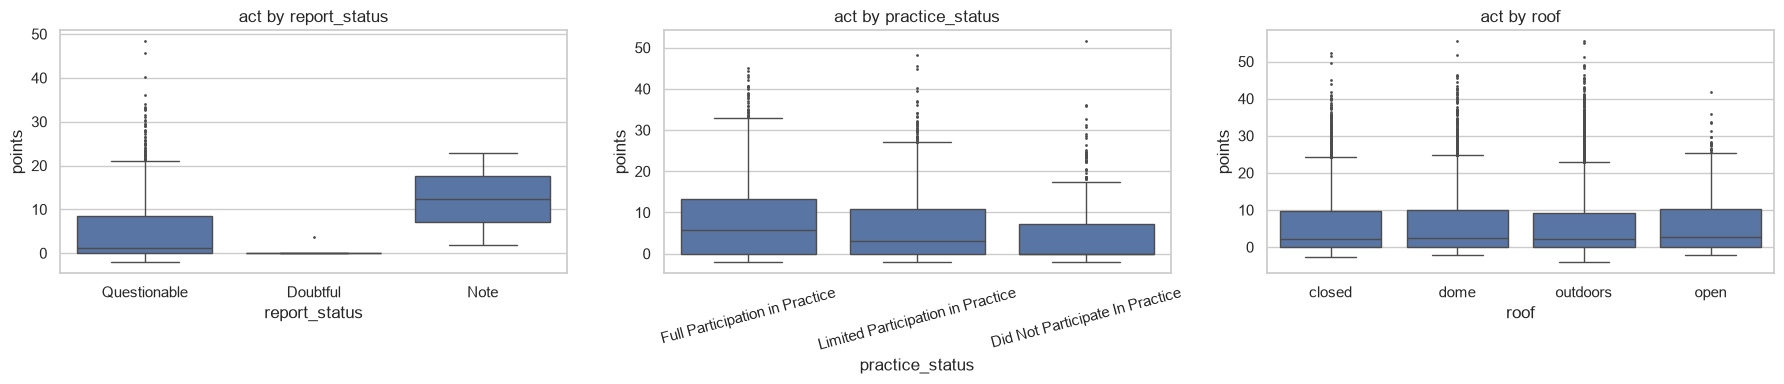

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.boxplot(df, x="report_status", y=TARGET, ax=axes[0], fliersize=1); axes[0].set(title="act by report_status", ylabel="points")
sns.boxplot(df, x="practice_status", y=TARGET, ax=axes[1], fliersize=1); axes[1].set(title="act by practice_status", ylabel="points")
axes[1].tick_params(axis="x", rotation=15)
sns.boxplot(df, x="roof", y=TARGET, ax=axes[2], fliersize=1); axes[2].set(title="act by roof", ylabel="points")
savefig("target_by_category")

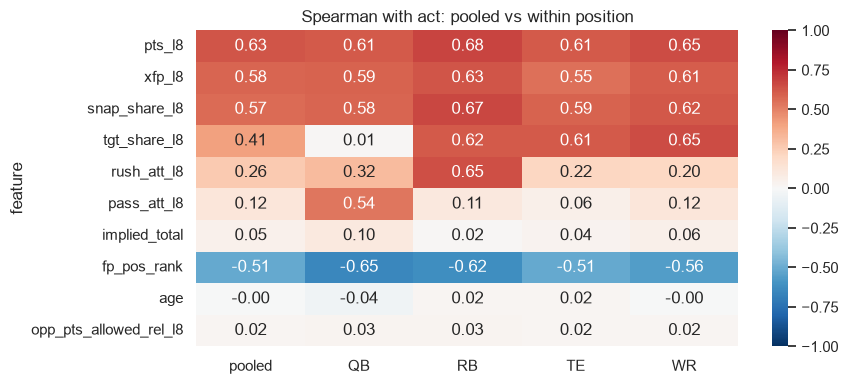

,pooled,QB,RB,TE,WR
feature,,,,,
pts_l8,0.628,0.611,0.679,0.612,0.653
xfp_l8,0.581,0.590,0.629,0.554,0.609
snap_share_l8,0.565,0.582,0.670,0.590,0.619
tgt_share_l8,0.411,0.010,0.616,0.614,0.650
rush_att_l8,0.261,0.316,0.645,0.216,0.205
pass_att_l8,0.118,0.535,0.107,0.055,0.120
implied_total,0.047,0.101,0.015,0.038,0.061
fp_pos_rank,-0.513,-0.653,-0.622,-0.513,-0.561
age,-0.001,-0.041,0.017,0.018,-0.000


In [23]:
# Simpson's paradox check: pooled vs within-position Spearman for top features
simp = []
for c in ["pts_l8", "xfp_l8", "snap_share_l8", "tgt_share_l8", "rush_att_l8", "pass_att_l8", "implied_total", "fp_pos_rank", "age", "opp_pts_allowed_rel_l8"]:
    row = {"feature": c, "pooled": stats.spearmanr(df[c], df[TARGET], nan_policy="omit")[0]}
    for pos, g in df.groupby("position"):
        row[pos] = stats.spearmanr(g[c], g[TARGET], nan_policy="omit")[0]
    simp.append(row)
simp = pd.DataFrame(simp).set_index("feature")
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(simp, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, vmin=-1, vmax=1)
ax.set(title="Spearman with act: pooled vs within position")
savefig("simpson_check")
simp

### 10b. Matchup and teammate features: do they add anything beyond the player himself?
Defense strength, the expected QB's passing ability and team context only matter on top of who the player is.
Partial Spearman of each feature with `act` **given the player's own `pts_l8`**, within position, on rows with
history. A pooled correlation would mostly measure how good the player is.

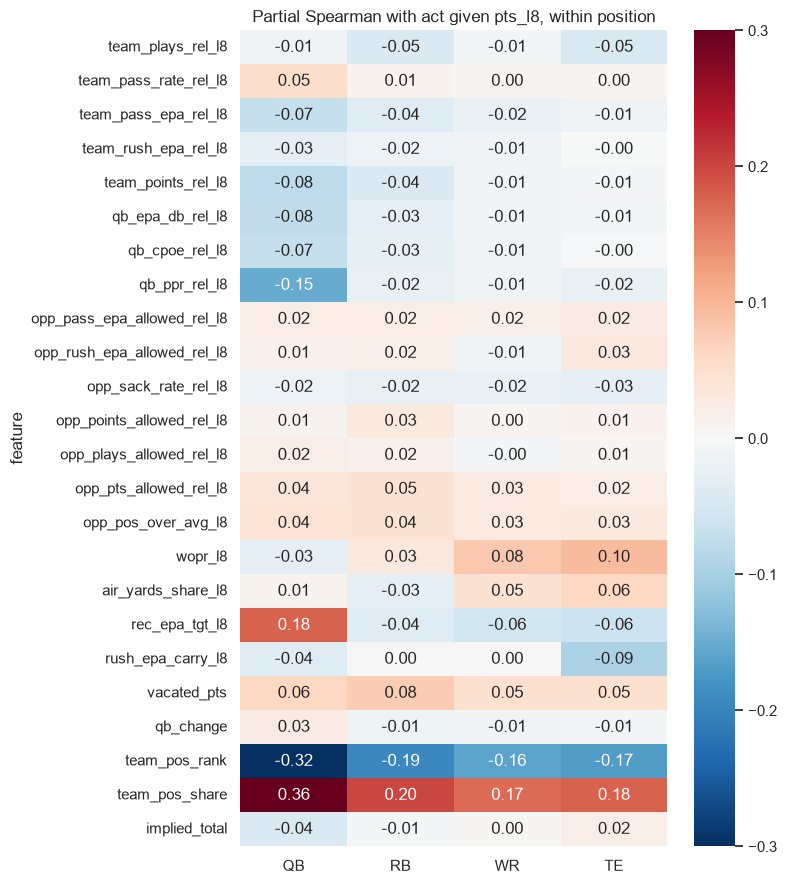

,QB,RB,WR,TE
feature,,,,
team_plays_rel_l8,-0.013,-0.046,-0.008,-0.049
team_pass_rate_rel_l8,0.052,0.012,0.005,0.005
team_pass_epa_rel_l8,-0.071,-0.037,-0.020,-0.012
team_rush_epa_rel_l8,-0.029,-0.017,-0.012,-0.000
team_points_rel_l8,-0.078,-0.042,-0.011,-0.007
qb_epa_db_rel_l8,-0.077,-0.030,-0.011,-0.007
qb_cpoe_rel_l8,-0.071,-0.027,-0.014,-0.003
qb_ppr_rel_l8,-0.150,-0.021,-0.014,-0.022
opp_pass_epa_allowed_rel_l8,0.023,0.023,0.019,0.024


In [24]:
def partial_spearman(x, y, z):
    # Spearman of x and y after removing the linear effect of z from both ranks
    rx, ry, rz = (pd.Series(v).rank().to_numpy() for v in (x, y, z))
    res = lambda a: a - np.polyval(np.polyfit(rz, a, 1), rz)
    return np.corrcoef(res(rx), res(ry))[0, 1]

MATCHUP = [c for c in df.columns if c.endswith("_rel_l8")] + ["opp_pos_over_avg_l8", "wopr_l8", "air_yards_share_l8",
           "rec_epa_tgt_l8", "rush_epa_carry_l8", "vacated_pts", "qb_change", "team_pos_rank", "team_pos_share", "implied_total"]
rows = []
for c in MATCHUP:
    row = {"feature": c}
    for pos, g in df[df.pts_l8.notna()].groupby("position"):
        ok = g[c].notna()
        row[pos] = partial_spearman(g.loc[ok, c], g.loc[ok, TARGET], g.loc[ok, "pts_l8"]) if ok.sum() > 200 else np.nan
    rows.append(row)
pm = pd.DataFrame(rows).set_index("feature")[["QB", "RB", "WR", "TE"]]
fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(pm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.3, vmax=.3, ax=ax)
ax.set(title="Partial Spearman with act given pts_l8, within position")
savefig("matchup_partial_correlations")
pm.round(3)

**Findings**


- **Strongest (Spearman with act):** `pts_season_avg` 0.67, `pts_l8` and `pts_l3` 0.63, **`sleeper_adp` -0.59 and `fp_ecr` -0.58** (preseason rank: lower = better), `snap_share_l3` 0.59, `xfp_l8` 0.58.
- **Mutual information ranks `xfp_l8` (0.31) right behind `pts_season_avg` (0.33) and `pts_l8` (0.32).** Expected points capture usage beyond what actual points show.
- **Next man up:** `team_pos_rank` (usage rank among available teammates) has Spearman -0.53, and `team_pos_share` +0.57. **`is_expected_qb` (the QB who started last game, if available) has +0.74**, the strongest single feature for QBs. Expected QBs average 15.5 points against 1.6, and the rule picks the real starter 89.8% of the time.
- **Section 10b, partial Spearman given the player's own `pts_l8`, within position.** This is what each feature adds beyond who the player is:
  - **Role this week is the biggest addition:** `team_pos_share` +0.37 QB, +0.17 to +0.20 others.
  - **`wopr_l8` +0.08 WR, +0.10 TE.** Air-yards plus target share says more than past points.
  - **`rec_epa_tgt_l8` -0.06 WR/TE:** efficient receivers regress.
  - **`vacated_pts` +0.05 to +0.08:** a missing teammate (Out, Doubtful, IR, cut or traded) promotes the rest.
  - **Defense strength: small but consistent at every position.** Schedule-adjusted `opp_pos_over_avg_l8` +0.03 to +0.04, `opp_pts_allowed_rel_l8` +0.02 to +0.05, `opp_pass_epa_allowed_rel_l8` +0.02.
  - **The QB's passing ability adds almost nothing for WR/TE once their own points are known** (`qb_epa_db_rel_l8` -0.01): the same QB is already in their history. It can matter when the QB changes (`qb_change`, 5.7% of team-weeks), an interaction the tree can learn. For QB rows, these features describe the *expected* QB, so they are negative for backups (`qb_ppr_rel_l8` -0.15).
  - Team pace and pass rate add almost nothing (|rho| <= 0.05).
- Game context is weak pooled (`implied_total` 0.05) and stronger within QBs (0.10). Rest, week, age and division games show almost nothing alone.
- **Categoricals:** `report_status` epsilon-squared **0.082**, now the strongest categorical (it was 0.000 when Sleeper had already removed the ruled-out players). Dunn's test separates Doubtful from Questionable (p < 0.001). `practice_status` 0.035. `team`, `opponent` and `roof` are near 0.
- **Simpson's paradox:** `tgt_share_l8` is 0.41 pooled but 0.62-0.65 for RB/WR/TE and 0.01 for QB. `pass_att_l8` is 0.12 pooled but **0.54 for QB**. `rush_att_l8` is 0.26 pooled but 0.65 for RB. Position must interact with the volume features, so use a tree model with `position`.

## 11. Leakage verdict
Every suspect from earlier sections in one place.

In [25]:
strong = ft[ft.spearman_target.abs() > .9]
print("features with |Spearman| > 0.9 vs target:", strong.feature.tolist())
leak = pd.DataFrame([
    {"column": "(any weekly projection)", "evidence": "none in the dataset by design; Sleeper's is only in benchmark_sleeper.parquet", "verdict": "n/a"},
    {"column": "fp_ecr, fp_pos_rank, sleeper_adp, sleeper_pos_adp", "evidence": "last scrape before the first kickoff / week-1 ADP; one value per player-season (checked)", "verdict": "keep"},
    {"column": "xfp_l3, xfp_l8, fp_over_xfp_l8", "evidence": "nflverse expected points of past regular-season games only; 1200/1200 recomputed values matched", "verdict": "keep"},
    {"column": "report_status / practice_status", "evidence": "official report published before the game", "verdict": "keep"},
    {"column": "*_l3, *_l8, pts_season_avg, opp_pts_allowed_rel_l8", "evidence": "as-of join strictly before the week; 400/400 recomputed values matched per feature", "verdict": "keep"},
    {"column": "position, team", "evidence": "point-in-time from nflverse weekly rosters", "verdict": "keep"},
    {"column": "games_season, weeks_since_played", "evidence": "counts of earlier games only", "verdict": "keep"},
    {"column": "kickoff", "evidence": "a timestamp; would let a model memorise weeks", "verdict": "drop"},
])
leak

features with |Spearman| > 0.9 vs target: []


,column,evidence,verdict
0,(any weekly projection),none in the dataset by design; Sleeper's is on...,n/a
1,"fp_ecr, fp_pos_rank, sleeper_adp, sleeper_pos_adp",last scrape before the first kickoff / week-1 ...,keep
2,"xfp_l3, xfp_l8, fp_over_xfp_l8",nflverse expected points of past regular-seaso...,keep
3,report_status / practice_status,official report published before the game,keep
4,"*_l3, *_l8, pts_season_avg, opp_pts_allowed_re...",as-of join strictly before the week; 400/400 r...,keep
5,"position, team",point-in-time from nflverse weekly rosters,keep
6,"games_season, weeks_since_played",counts of earlier games only,keep
7,kickoff,a timestamp; would let a model memorise weeks,drop


**Findings**


- **No weekly projection from any platform is in the data.** The yearly rankings are true preseason snapshots: the FantasyPros scrape is 4-9 days before the first kickoff, Sleeper ADP is taken at week 1, and each has one value per player-season.
- No feature has |Spearman| > 0.9 with the target (the maximum is 0.67).
- History, ff_opportunity and defense features were all re-audited by recomputation: 400 of 400 values per feature, and 1,200 of 1,200 for `xfp`. The audit caught one bug: playoff weeks in ff_opportunity collided with the next season's weeks 1-4 in the time index. It was fixed, and the features are now regular season only.
- Team and position are point-in-time (weekly rosters). `kickoff` is dropped.
- **New features re-audited:** `opp_pass_epa_allowed_l8`, `wopr_l8` and `opp_pos_over_avg_l8` 0 mismatches each in 300-row hand recomputations. The expected-QB rule was validated against who actually threw the most passes (89.8% match). **A first version ranked QBs by recent usage and flagged a "QB change" in 21% of team-weeks**, against the true 5.7% (Joe Flacco 2023 was ranked behind a teammate with more history). It was fixed to "last game's starter, if available".
- Team, QB and defense values are **relative to the league average that week**. That is point-in-time (every team's trailing value is known before the week) and removes season-level drift.

## 12. Train/test representativeness
The test set (2026 weeks 1-7) only covers early-season weeks, so where it matters the comparison is also made
against train restricted to weeks 1-7.

In [26]:
test = test_raw.copy()
apply_null_tokens(test)  # same rule as train (section 5)
early = df[df.week <= 7]

def psi(a, b, bins=10):
    a, b = a.dropna(), b.dropna()
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan
    pa = np.histogram(a.clip(edges[0], edges[-1]), edges)[0] / len(a) + 1e-6
    pb = np.histogram(b.clip(edges[0], edges[-1]), edges)[0] / len(b) + 1e-6
    return float(np.sum((pb - pa) * np.log(pb / pa)))

rows = []
for c in [x for x in num if x != "week"] + [TARGET]:
    rows.append({"feature": c, "psi_all_train": psi(df[c], test[c]), "psi_weeks_1_7": psi(early[c], test[c]),
                 "ks_p_weeks_1_7": stats.ks_2samp(early[c].dropna(), test[c].dropna()).pvalue})
for c in ["position", "roof", "report_status"]:
    ct = pd.crosstab(pd.concat([early[c], test[c]]).fillna("NA"), np.r_[np.zeros(len(early)), np.ones(len(test))])
    rows.append({"feature": c, "chi2_p_weeks_1_7": stats.chi2_contingency(ct)[1]})
rep = pd.DataFrame(rows).sort_values("psi_weeks_1_7", ascending=False)
rep.head(12)

,feature,psi_all_train,psi_weeks_1_7,ks_p_weeks_1_7,chi2_p_weeks_1_7
46,qb_cpoe_rel_l8,0.202,0.212,0.000,NaN
0,total_line,0.194,0.148,0.000,NaN
40,team_plays_rel_l8,0.078,0.116,0.000,NaN
48,opp_pass_epa_allowed_rel_l8,0.121,0.109,0.000,NaN
51,opp_points_allowed_rel_l8,0.089,0.107,0.000,NaN
41,team_pass_rate_rel_l8,0.052,0.080,0.000,NaN
45,qb_epa_db_rel_l8,0.096,0.071,0.000,NaN
49,opp_rush_epa_allowed_rel_l8,0.035,0.059,0.000,NaN
52,opp_plays_allowed_rel_l8,0.045,0.058,0.000,NaN
50,opp_sack_rate_rel_l8,0.046,0.057,0.000,NaN


           pair  adversarial_auc
0  2022 vs 2023            0.833
1  2023 vs 2024            0.860
2  2024 vs 2025            0.810
3  2025 vs 2026            0.756


top drivers 2025 vs 2026: {'team_plays_rel_l8': 261, 'team_pass_rate_rel_l8': 250, 'opp_pass_epa_allowed_rel_l8': 235, 'qb_ppr_rel_l8': 200, 'team_pass_epa_rel_l8': 192}


same 2025 vs 2026 test with row-shuffled folds (trap 1): 1.000
time order: train max 2026-01-04 20:20:00 < test min 2026-09-09 20:20:00 -> True


test rows whose player appears in train: 84.8% (expected: same league, new season)
position mix train(1-7) vs test: {'WR': 0.38, 'RB': 0.257, 'TE': 0.225, 'QB': 0.138} {'WR': 0.372, 'TE': 0.246, 'RB': 0.24, 'QB': 0.142}


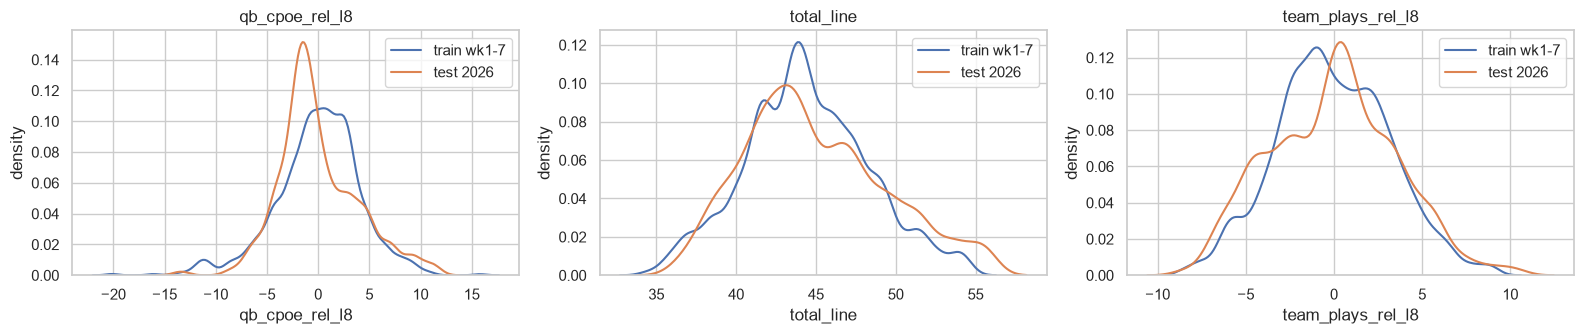

In [27]:
# Adversarial validation, done carefully. Two traps found while building this cell:
# 1. Row-shuffled folds put players of the same game in train and validation folds; the classifier then
#    recognises games by their exact Vegas line (AUC 0.96 from total_line/spread alone). Folds are grouped by game.
# 2. Season-constant player values (pts_prev_season) still identify a player-season across weeks, so any
#    single AUC is inflated. The fair reading is a benchmark: 2026 vs 2025 against each pair of train seasons.
from sklearn.model_selection import StratifiedGroupKFold
adv_cols = [c for c in num if c != "week"] + ["position", "roof", "report_status"]
both = pd.concat([df[df.week <= 7], test], ignore_index=True)
for c in ["position", "roof", "report_status"]:
    both[c] = both[c].astype("category")
game = both.season.astype(str) + "_" + both.week.astype(str) + "_" + both[["team", "opponent"]].min(axis=1)
clf = lgb.LGBMClassifier(n_estimators=200, learning_rate=.05, num_leaves=15, verbose=-1, random_state=SEED)
bench = []
for a, b in [(2022, 2023), (2023, 2024), (2024, 2025), (2025, 2026)]:
    m = both.season.isin([a, b])
    auc = cross_val_score(clf, both.loc[m, adv_cols], both.loc[m, "season"].eq(b), groups=game[m],
                          cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc").mean()
    bench.append({"pair": f"{a} vs {b}", "adversarial_auc": auc})
print(pd.DataFrame(bench))
m = both.season.isin([2025, 2026])
imp = pd.Series(clf.fit(both.loc[m, adv_cols], both.loc[m, "season"].eq(2026)).feature_importances_, adv_cols).sort_values(ascending=False)
print("top drivers 2025 vs 2026:", imp.head(5).to_dict())
games_auc = cross_val_score(clf, both.loc[m, adv_cols], both.loc[m, "season"].eq(2026),
                            cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc").mean()
print(f"same 2025 vs 2026 test with row-shuffled folds (trap 1): {games_auc:.3f}")
print("time order: train max", df.kickoff.max(), "< test min", test.kickoff.min(), "->", df.kickoff.max() < test.kickoff.min())
overlap = test.player_id.isin(df.player_id).mean()
print(f"test rows whose player appears in train: {overlap:.1%} (expected: same league, new season)")
print("position mix train(1-7) vs test:", early.position.value_counts(normalize=True).round(3).to_dict(), test.position.value_counts(normalize=True).round(3).to_dict())
top_shift = rep.dropna(subset=["psi_weeks_1_7"]).head(3).feature.tolist()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, c in zip(axes, top_shift):
    sns.kdeplot(early[c].dropna(), ax=ax, label="train wk1-7"); sns.kdeplot(test[c].dropna(), ax=ax, label="test 2026")
    ax.set(title=f"{c}", xlabel=c, ylabel="density"); ax.legend()
savefig("train_test_shift")

**Findings**


- Time order is clean (train ends 2026-01-04, test starts 2026-09-09).
- PSI test vs train weeks 1-7: **`qb_cpoe_rel_l8` 0.21**, even after the league-relative fix (it was 0.17 raw). Its shift is not a league offset, and it adds nothing beyond QB EPA (10b), so **it is dropped**. `total_line` 0.15. The raw team features were drifting (`team_plays_l8` 0.23, `qb_cpoe_l8` 0.17, `opp_pass_epa_allowed_l8` 0.12); as league-relative values they are 0.12 / dropped / 0.11, and the rest are under 0.11.
- **Adversarial validation (game-grouped folds, benchmarked against training-season pairs):** 2025 vs 2026 separates at **0.756, below every training pair (0.81-0.86)**. The pairs rose for everyone, because team-level features identify team-seasons, but the test season is still the least distinguishable.
- Position mix matches (QB 14%, RB 24-26%, WR 37-38%, TE 23-25%). The test set is representative of weeks 1-7.

## Summary


**Most important findings**
1. The target is 37% zeros, right-skewed, with valid negatives. Use squared-error or Tweedie loss on the raw target, RMSE plus MAE, and also report played-only rows.
2. **Availability is now part of the problem:** `report_status` (Doubtful 0.5% played, Questionable 68%) and `weeks_since_played` (30% to 74% zeros) are the key signals for who plays. Sleeper's final snapshot knows game-day inactives, which no pre-game fact has.
3. The best predictors are the player's own history (`pts_season_avg`, `pts_l8`), the preseason rankings, role this week (`is_expected_qb`, `team_pos_share`) and expected points. Volume features need position interactions (Simpson's paradox).
4. **Beyond the player himself:** role and next-man-up signals are strong. WOPR helps receivers, efficiency regresses, and defense strength is small but consistent. QB passing ability matters mainly through QB changes.
5. Drop `kickoff`, `name`, `gsis_id`, `team`, `opponent`, `rec_tgt_l3`, `rec_tgt_l8` and `qb_cpoe_rel_l8` (drift). Keep Doubtful as its own level.
6. The 2026 test set is representative (adversarial AUC 0.756, below season-to-season norms).

**Cleaning log**

| step | column | rows | action |
|---|---|---|---|
| null tokens | `practice_status` (whitespace) | 26 | NaN |
| invalid value (recommended) | `snap_share_l3` > 1 | 4 | set NaN |

**Next steps:** processing per `eda_decisions.yml`: time split by season, 2026 holdout, Sleeper scored only from the benchmark file on the same rows.

In [28]:
DECISIONS_RECS = {
    "drop_columns": [
        {"column": "kickoff", "reason": "timestamp, not a feature", "status": "recommended"},
        {"column": "name", "reason": "identifier", "status": "recommended"},
        {"column": "gsis_id", "reason": "identifier (NFL id)", "status": "recommended"},
        {"column": "team", "reason": "identity effect eps2 0.004; would memorise team-seasons", "status": "recommended"},
        {"column": "opponent", "reason": "identity effect eps2 0.000; strength captured by the opp_* defense features", "status": "recommended"},
        {"column": "rec_tgt_l3", "reason": "r=0.97 with tgt_share_l3", "status": "recommended"},
        {"column": "rec_tgt_l8", "reason": "r=0.98 with tgt_share_l8", "status": "recommended"},
        {"column": "qb_cpoe_rel_l8", "reason": "PSI 0.21 train vs test even league-relative; adds nothing beyond qb_epa_db_rel_l8", "status": "recommended"},
    ],
    "leakage": [
        {"column": "kickoff", "evidence": "timestamp", "verdict": "drop"},
        {"column": "fp_ecr", "evidence": "last FantasyPros scrape before the first kickoff; one value per player-season", "verdict": "keep"},
        {"column": "sleeper_adp", "evidence": "ADP stored with week-1 projections; frozen for the season", "verdict": "keep"},
        {"column": "xfp_l8", "evidence": "expected points of past regular-season games; 1200/1200 recomputed values matched", "verdict": "keep"},
        {"column": "pts_l3", "evidence": "history features audited: 400/400 recomputed values matched", "verdict": "keep"},
        {"column": "opp_pass_epa_allowed_rel_l8", "evidence": "team-stats history audited 300/300; league mean uses only that week's pre-game values", "verdict": "keep"},
        {"column": "is_expected_qb", "evidence": "last game's starter if available; matches the real starter 89.8%", "verdict": "keep"},
    ],
    "missing_indicators": [
        {"column": "pts_l8", "mechanism": "MAR", "reason": "whole history block missing for debuts; act 1.6 vs 6.0"},
        {"column": "pts_prev_season", "mechanism": "MAR", "reason": "rookies / absent last season; act 3.8 vs 6.3"},
        {"column": "xfp_l8", "mechanism": "MAR", "reason": "no ff_opportunity history; act 1.0 vs 6.1"},
        {"column": "fp_ecr", "mechanism": "MNAR", "reason": "unranked preseason; act 1.4 vs 6.8"},
        {"column": "sleeper_adp", "mechanism": "MNAR", "reason": "undrafted preseason; act 2.3 vs 7.3"},
        {"column": "report_status", "mechanism": "MNAR", "reason": "missing = not on the injury report; own level"},
        {"column": "practice_status", "mechanism": "MNAR", "reason": "missing = not on the practice report; own level"},
    ],
    "capping": [],
    "transforms": [],
    "rare_level_grouping": [],
    "manual_treatment": [
        {"column": "player_id", "kind": "high_card_categorical", "cardinality": 1012, "examples": ["1029", "1034", "1049"]},
    ],
    "redundant_pairs": [
        {"columns": ["rec_tgt_l8", "tgt_share_l8"], "measure": "pearson", "value": 0.983, "suggestion": "drop rec_tgt_l8 (and rec_tgt_l3)"},
        {"columns": ["sleeper_pos_adp", "fp_pos_rank"], "measure": "spearman", "value": 0.955, "suggestion": "keep both; they disagree on the undrafted tail"},
    ],
    "datetime_parts": [],
    "target": {"transform": None, "class_weights": None,
               "reason": "37% zeros with negatives; lineups need expected points: squared-error on the raw target, Tweedie as an experiment"},
}
DECISIONS_VALIDATION = {
    "split": "already_split",
    "group_column": "player_id",
    "stratify_on": [],
    "holdout": "2026 weeks 1-7 (test file); inside train an expanding season split: fit 2022-2023 -> validate 2024, fit 2022-2024 -> validate 2025",
    "representativeness_issues": [
        {"feature": "total_line", "psi": 0.15, "note": "higher 2026 totals; moderate"},
        {"feature": "qb_cpoe_rel_l8", "psi": 0.21, "note": "dropped"},
        {"feature": "team_plays_rel_l8", "psi": 0.12, "note": "league-relative (raw was 0.23)"},
        {"feature": "opp_pass_epa_allowed_rel_l8", "psi": 0.11, "note": "league-relative"},
    ],
    "metric": {"primary": "rmse", "secondary": ["mae", "within_week_spearman", "bias", "rmse_played_only"],
               "reason": "lineup value is expected points (mean); MAE rewards median shrinkage; played-only isolates performance from availability"},
}
DECISIONS_OPEN = [
    "Sleeper's final snapshot knows game-day inactives (it projects 0 for 96% of players who end up not playing). Should the headline comparison include those rows (fair to the use case) or only players who played (fair to the model)? Both are reported.",
]

In [29]:
def cut_rule(col):
    return RULES.get(col)

decisions = {
    "meta": {"dataset": "player_games", "eda_notebook": "eda_player_games.ipynb", "created": "2026-10-28",
             "files": {"train": "research/data/player_games_train.parquet", "test": "research/data/player_games_test.parquet"},
             "rules_file_found": True},
    "problem": {"type": "regression", "target": TARGET, "positive_class": None, "target_classes": [],
                "unit_of_observation": "one QB/RB/WR/TE in one regular-season week: on the 53-man roster, recently active or preseason-ranked, not listed Out",
                "key": KEY, "entity_column": ENTITY, "time_column": "kickoff",
                "rows_missing_target": {"count": int(df_raw[TARGET].isna().sum()), "meaning": "unknown"}},
    "columns": {c: {"type": types.loc[c, "type"], "missing_pct": round(float(types.loc[c, "missing_pct"]), 3)} for c in df_raw.columns},
    "cleaning": {
        "parsing_fixes": [],
        "null_tokens": NULL_TOKENS,
        "sentinels_to_nan": [],
        "spelling_mappings": [],
        "duplicates": {"full_row": {"count": int(full_dup), "action": "drop", "status": "applied"},
                       "conflicting_key": {"count": int(dup_key), "action": "keep_all", "status": "applied", "reason": "no duplicated keys"}},
        "invalid_values": [{"column": r.column, "rule": r.issue, "count": int(r["count"]), "action": "set_nan", "status": "recommended",
                            "reason": "outside the physically possible range"} for _, r in inval[inval["count"] > 0].iterrows()],
        "outlier_removals": [],
    },
    "recommendations": DECISIONS_RECS,
    "validation": DECISIONS_VALIDATION,
    "open_questions": DECISIONS_OPEN,
}
decisions["columns"]["kickoff"]["notes"] = "timestamp; drop as a feature"
with open("eda_decisions.yml", "w") as fh:
    yaml.safe_dump(decisions, fh, sort_keys=False, allow_unicode=True)
print("eda_decisions.yml written; parses:", isinstance(yaml.safe_load(open("eda_decisions.yml")), dict))
print("cleaning log:", cleaning_log)

eda_decisions.yml written; parses: True
cleaning log: [('null_tokens', 'practice_status', 26, 'disguised null -> NaN')]
